# 감귤 도매시장 판매데이터(`data/kat*.csv`) 전처리 및 다차원 EDA 분석
> **작성 목적**: `data/` 디렉터리에 수집된 전국 32개 공영도매시장 감귤 거래 정산 데이터(`data/kat*.csv`, 약 124만 건)를 통합 전처리하고, **경매 vs 수의계약 제외 비교, 날짜별, 등급별, 종류별(품종별), 크기별** 판매수량(거래물량)과 판매가격을 심층 분석 및 시각화합니다.
> **aT 공영도매시장 공식 표준 품종 코드 매핑**:
> - `gds_sclsf_cd` 07: **한라봉**
> - `gds_sclsf_cd` 08: **천혜향**
> - `gds_sclsf_cd` 09: **레드향**
> - `gds_sclsf_cd` 10: **카라향**
> - `gds_sclsf_cd` 11: **황금향**

---

### 분석 파이프라인 목차
1. **환경 설정 및 한글 폰트 설정**: 데이터 분석 라이브러리 로드 및 시각화 환경 구성 (`Malgun Gothic`)
2. **데이터 수집 및 병합 (Ingestion)**: `data/kat*.csv` (497개 분할 파일) 일괄 로드 및 중복 레코드 정제
3. **데이터 정제 및 전처리 (Preprocessing & Cleaning)**:
   - 거래일자 날짜형(`datetime`) 변환 및 시계열 파생변수 생성
   - **aT 공식 표준 품종 코드 매핑 (07: 한라봉, 08: 천혜향, 09: 레드향, 10: 카라향, 11: 황금향)**
   - 음수/오류 거래 및 극단 이상치 제거
   - 핵심 지표(`volume_kg`, `box_qty`, `total_price`, `box_price`, `unit_price_kg`) 산출
4. **【거래유형 분석】 수의계약 제외에 따른 판매가격 변동 검토 (경매 vs 수의계약)**:
   - 거래유형별(경매 vs 수의계약) 물량 및 단가 격차 비교
   - 수의계약 제외 시 품종별/등급별 평균 판매가격 변동폭(%) 검토
   - 시계열(월별) 단가 추이 비교 (전체 vs 수의계약 제외 순수 경매)
5. **[날짜별] 판매수량 및 판매가격 시계열 분석**: 일별/월별 물량 추이 및 단가 변동 수급 분석 (2축 Dual-Axis 차트)
6. **[등급별] 판매수량 및 판매가격 분석**: 등급별 점유율, 평균 단가 및 가격 분포(Boxplot)
7. **[종류별] 판매수량 및 판매가격 분석**: 주요 품종별(하우스감귤, 조생귤, 한라봉, 천혜향, 레드향 등) 물량 및 단가 프리미엄 분석
8. **[크기별] 판매수량 및 판매가격 분석 (품종별 세부 분류 포함)**:
   - 8-1) 전체 감귤 크기 규격별 판매물량 및 단가 분석 (50내 -> 45내 -> 40내 -> 35내 -> 소 -> 중 -> 대 -> 특대)
   - 8-2) **주요 품종별(하우스감귤, 조생귤, 한라봉, 천혜향, 레드향) 크기 규격별 세부 분류 및 단가 비교**
   - 8-4) **상자 크기별(3kg, 5kg, 10kg) x 과수 규격(50내/45내/40내/35내) 품종별 평균가격 비교**
9. **[크기별 × 품종별] 항목별 날짜에 따른 거래량 및 가격 시계열 분석**:
   - 9-1) 품종별 주요 크기 규격의 월별 거래물량(톤) 시계열 추이
   - 9-2) 품종별 주요 크기 규격의 월별 kg당 평균가격(원/kg) 시계열 추이
   - 9-3) 대표 품종 및 크기 항목별 날짜에 따른 거래량 & 가격 2축(Dual-Axis) 추이
   - 9-4) [품종 × 등급] 및 [품종 × 크기] 교차 단가 히트맵
10. **전처리 완료 데이터 내보내기 (Export)**: 모델링 및 후속 분석용 정제 데이터셋 CSV 저장

## 1. 환경 설정 및 한글 폰트 설정
- 시각화 시 한글 깨짐 방지를 위해 `Malgun Gothic` 폰트 및 음수 기호 설정을 적용합니다.

In [1]:
import os
import glob
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# 경고 메시지 무시
warnings.filterwarnings('ignore')

# Matplotlib 한글 폰트 및 마이너스 부호 설정
plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Seaborn 테마 설정
sns.set_theme(style='whitegrid', font='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False

print("환경 설정 완료: pandas, numpy, matplotlib, seaborn 로드 성공")

환경 설정 완료: pandas, numpy, matplotlib, seaborn 로드 성공


## 2. 데이터 수집 및 병합 (Data Ingestion)
- `data/` 디렉터리 내의 `data/kat*.csv` (497개 분할 파일)을 탐색하여 병합합니다.
- 0바이트 빈 파일을 필터링하고 중복 데이터를 제거하여 단일 데이터프레임으로 통합합니다.

In [2]:
# 1) data/ 디렉터리 내 kat*.csv 파일 검색 (fallback: output/kat*.csv)
data_dir = Path("data")
data_files = sorted(glob.glob(str(data_dir / "kat*.csv")))

if not data_files:
    print("data/kat*.csv 파일이 없어 output/ 디렉터리에서 검색합니다.")
    data_dir = Path("output")
    data_files = sorted(glob.glob(str(data_dir / "kat_sale_citrus*.csv")))

# 0바이트 파일 및 _all.csv 제외한 유효 CSV 파일 선택
valid_files = [f for f in data_files if '_all.csv' not in f and os.path.getsize(f) > 50]
print(f"발견된 유효한 데이터 파일 수: {len(valid_files)}개 (대상 디렉터리: {data_dir.resolve()})")

# 2) 필요한 핵심 컬럼 선별 로드 (거래구분 trd_se 포함)
target_cols = [
    'trd_clcln_ymd', 'whsl_mrkt_cd', 'whsl_mrkt_nm', 'trd_se',
    'gds_sclsf_cd', 'gds_sclsf_nm', 'grd_cd', 'grd_nm', 'sz_cd', 'sz_nm',
    'pkg_cd', 'pkg_nm', 'unit_nm', 'unit_qty', 'unit_tot_qty', 'avgprc', 'totprc'
]

t0 = time.time()
dfs = []
for file_path in valid_files:
    try:
        df_sub = pd.read_csv(file_path, usecols=lambda c: c in target_cols, low_memory=False, encoding='utf-8-sig')
        dfs.append(df_sub)
    except Exception as exc:
        print(f"파일 로드 오류 건너뜀: {file_path} - {exc}")

df_raw = pd.concat(dfs, ignore_index=True)
elapsed = time.time() - t0
print(f"\n데이터 로드 완료! (소요시간: {elapsed:.2f}초)")
print(f"- 원본 데이터 총 행 수: {len(df_raw):,} 건")
print(f"- 원본 데이터 컬럼 수: {df_raw.shape[1]} 개")

# 중복 레코드 제거
raw_count = len(df_raw)
df_raw = df_raw.drop_duplicates()
print(f"- 중복 제거 후 행 수: {len(df_raw):,} 건 ({raw_count - len(df_raw):,}건 중복 제거됨)")
df_raw.head(3)

발견된 유효한 데이터 파일 수: 497개 (대상 디렉터리: D:\aiproject\ugasungsi\data)

데이터 로드 완료! (소요시간: 8.05초)
- 원본 데이터 총 행 수: 1,247,915 건
- 원본 데이터 컬럼 수: 17 개
- 중복 제거 후 행 수: 1,246,519 건 (1,396건 중복 제거됨)


,avgprc,gds_sclsf_cd,gds_sclsf_nm,grd_cd,grd_nm,pkg_cd,pkg_nm,sz_cd,sz_nm,totprc,trd_clcln_ymd,trd_se,unit_nm,unit_qty,unit_tot_qty,whsl_mrkt_cd,whsl_mrkt_nm
0,6519.048,1,조생귤,12,상,101,상자,100,.,6154700.0,2021-01-04,경매,kg,5.0,4485.0,210009,부산반여
1,7994.030,1,조생귤,12,상,101,상자,100,.,21994500.0,2021-01-04,경매,kg,5.0,12630.0,210009,부산반여
2,15383.333,1,조생귤,12,상,101,상자,100,.,5875500.0,2021-01-04,경매,kg,10.0,4140.0,210009,부산반여


## 3. 데이터 정제 및 전처리 (Data Cleaning & Feature Engineering)

### 정제 작업 상세:
1. **날짜 변환 및 파생변수 생성**: `trd_clcln_ymd` 문자열을 `datetime`으로 변환 후 `year`, `month`, `year_month`, `weekday` 생성
2. **거래 무효치 필터링**: 음수/0 거래수량 및 거래금액 정제 (`unit_tot_qty > 0`, `totprc > 0`, `avgprc > 0`)
3. **aT 공영도매시장 공식 표준 품종 코드 매핑**:
   - `gds_sclsf_cd` 07 (7) $
ightarrow$ **한라봉** (정상 복원)
   - `gds_sclsf_cd` 08 (8) $
ightarrow$ **천혜향** (정상 복원)
   - `gds_sclsf_cd` 09 (9) $
ightarrow$ **레드향**
   - `gds_sclsf_cd` 10 $
ightarrow$ **카라향**
   - `gds_sclsf_cd` 11 $
ightarrow$ **황금향**
   - 그 외 기존 소분류명 및 일반 감귤 표준 코드 적용
4. **거래구분(`trd_se`) 정제**: 경매, 수의계약(정가수의), 기타 거래 구분 컬럼(`trd_type`) 생성
5. **등급 및 크기 명칭 표준화**: 잡음 기호(`.`, 공백)를 `무등급/미지정`, `미지정`으로 표준화
6. **핵심 분석 지표 생성**:
   - `volume_kg`: 총 판매물량 (kg)
   - `box_qty`: 환산 판매상자 수 (`unit_tot_qty / unit_qty`)
   - `total_price`: 총 판매금액 (원)
   - `box_price`: 상자(포장)당 평균가격 (원/상자)
   - `unit_price_kg`: kg당 평균 판매단가 (`total_price / volume_kg`, 원/kg)
7. **단가 이상치 필터링**: kg당 단가가 100원 미만이거나 100,000원 초과인 극단 입력오류 정제

In [3]:
df = df_raw.copy()

# 1) 날짜 변환 및 시계열 파생변수
df['date'] = pd.to_datetime(df['trd_clcln_ymd'], errors='coerce')
df = df.dropna(subset=['date']).copy()
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['year_month'] = df['date'].dt.to_period('M').astype(str)
df['day_name'] = df['date'].dt.day_name()
weekday_kor = {'Monday': '월', 'Tuesday': '화', 'Wednesday': '수', 'Thursday': '목', 'Friday': '금', 'Saturday': '토', 'Sunday': '일'}
df['weekday'] = df['day_name'].map(weekday_kor)

# 2) 유효 거래 수량 및 금액 필터링 (음수 및 0 정산내역 제거)
valid_mask = (df['unit_tot_qty'] > 0) & (df['totprc'] > 0) & (df['avgprc'] > 0)
df = df[valid_mask].copy()

# 3) aT 공영도매시장 공식 표준 품종 코드 매핑 (07: 한라봉, 08: 천혜향, 09: 레드향, 10: 카라향, 11: 황금향)
citrus_variety_map = {
    0: '감귤(일반)', '0': '감귤(일반)', '00': '감귤(일반)',
    1: '조생귤', '1': '조생귤', '01': '조생귤',
    2: '중생귤', '2': '중생귤', '02': '중생귤',
    3: '만생귤', '3': '만생귤', '03': '만생귤',
    4: '비가림감귤', '4': '비가림감귤', '04': '비가림감귤',
    5: '하우스감귤', '5': '하우스감귤', '05': '하우스감귤',
    6: '극조생감귤', '6': '극조생감귤', '06': '극조생감귤',
    7: '한라봉', '7': '한라봉', '07': '한라봉',
    8: '천혜향', '8': '천혜향', '08': '천혜향',
    9: '레드향', '9': '레드향', '09': '레드향',
    10: '카라향', '10': '카라향',
    11: '황금향', '11': '황금향',
    12: '하루미', '12': '하루미',
    13: '온주', '13': '온주',
    15: '성전', '15': '성전',
    17: '홍미향', '17': '홍미향',
    19: '타이벡감귤', '19': '타이벡감귤',
    20: '풋귤(청귤)', '20': '풋귤(청귤)',
    23: '미니향', '23': '미니향',
    32: '유라와세', '32': '유라와세',
    34: '산하홍', '34': '산하홍',
    98: '감귤(수입)', '98': '감귤(수입)',
    99: '기타', '99': '기타'
}

# aT 표준 만감류 코드 오버라이드 매핑
user_override_map = {
    7: '한라봉', '7': '한라봉', '07': '한라봉',
    8: '천혜향', '8': '천혜향', '08': '천혜향',
    9: '레드향', '9': '레드향', '09': '레드향',
    10: '카라향', '10': '카라향',
    11: '황금향', '11': '황금향'
}

df['variety'] = df['gds_sclsf_cd'].map(user_override_map).combine_first(df['gds_sclsf_nm']).combine_first(df['gds_sclsf_cd'].map(citrus_variety_map)).fillna('기타')

# 4) 거래구분(trd_se) 표준화: 경매 vs 수의계약(정가수의)
df['trd_se_raw'] = df['trd_se'].fillna('기타').astype(str)
df['is_negotiated'] = df['trd_se_raw'].str.contains('수의', na=False)
df['is_auction'] = df['trd_se_raw'].str.contains('경매', na=False)
df['trd_type'] = np.where(df['is_negotiated'], '수의계약', np.where(df['is_auction'], '경매', '기타'))

# 5) 등급(Grade) 표준화
df['grade'] = df['grd_nm'].fillna('.').astype(str).str.strip()
df['grade'] = df['grade'].replace({'.': '무등급/미지정', '': '무등급/미지정', 'nan': '무등급/미지정'})

# 6) 크기(Size) 표준화
df['size'] = df['sz_nm'].fillna('.').astype(str).str.strip()
df['size'] = df['size'].replace({'.': '미지정', '': '미지정', 'nan': '미지정'})

# 7) 핵심 분석 수치 지표 계산
df['volume_kg'] = pd.to_numeric(df['unit_tot_qty'], errors='coerce').fillna(0.0)
df['unit_weight'] = pd.to_numeric(df['unit_qty'], errors='coerce').fillna(0.0)
df['box_qty'] = np.where(df['unit_weight'] > 0, df['volume_kg'] / df['unit_weight'], np.nan)
df['total_price'] = pd.to_numeric(df['totprc'], errors='coerce').fillna(0.0)
df['box_price'] = pd.to_numeric(df['avgprc'], errors='coerce').fillna(0.0)
df['unit_price_kg'] = df['total_price'] / (df['volume_kg'] + 1e-8)

# 8) kg당 단가 극단 이상치 제거 (정상 도매 단가 범위: 100원/kg ~ 100,000원/kg)
df = df[(df['unit_price_kg'] >= 100) & (df['unit_price_kg'] <= 100000)].copy()

print(f"전처리 완료 최종 데이터 행 수: {len(df):,} 건")
print(f"조회 기간: {df['date'].min().strftime('%Y-%m-%d')} ~ {df['date'].max().strftime('%Y-%m-%d')}")
print(f"포함된 전국 도매시장 수: {df['whsl_mrkt_nm'].nunique()}개 도매시장")
print(f"포함된 감귤 품종 수: {df['variety'].nunique()}개")
print(f"품종별 상위 레코드 수:\n{df['variety'].value_counts().head(8)}")
display(df[['date', 'whsl_mrkt_nm', 'trd_type', 'variety', 'grade', 'size', 'volume_kg', 'box_qty', 'box_price', 'unit_price_kg']].head())

전처리 완료 최종 데이터 행 수: 1,243,424 건
조회 기간: 2021-01-02 ~ 2026-11-11
포함된 전국 도매시장 수: 32개 도매시장
포함된 감귤 품종 수: 23개
품종별 상위 레코드 수:
variety
하우스감귤    322086
조생귤      316478
기타       160751
한라봉      132842
극조생감귤     92528
비가림감귤     63145
레드향       52851
천혜향       48396
Name: count, dtype: int64


,date,whsl_mrkt_nm,trd_type,variety,grade,size,volume_kg,box_qty,box_price,unit_price_kg
0,2021-01-04,부산반여,경매,조생귤,상,미지정,4485.0,897.0,6519.048,1372.285396
1,2021-01-04,부산반여,경매,조생귤,상,미지정,12630.0,2526.0,7994.030,1741.448931
2,2021-01-04,부산반여,경매,조생귤,상,미지정,4140.0,414.0,15383.333,1419.202899
3,2021-01-04,부산반여,경매,한라봉,상,미지정,480.0,160.0,17733.333,5982.916667
4,2021-01-04,부산반여,경매,한라봉,상,미지정,1494.0,498.0,18818.182,5959.772423


### 전처리 요약 및 수치 기술통계

In [4]:
summary_stats = pd.DataFrame({
    '총 거래 건수': [f"{len(df):,} 건"],
    '포함 도매시장 수': [f"{df['whsl_mrkt_nm'].nunique()} 개 시장"],
    '누적 거래물량(톤)': [f"{df['volume_kg'].sum() / 1000:,.1f} 톤"],
    '누적 환산상자수': [f"{df['box_qty'].sum():,.0f} 상자"],
    '총 거래금액(억원)': [f"{df['total_price'].sum() / 1e8:,.1f} 억원"],
    '평균 kg당 단가': [f"{df['total_price'].sum() / df['volume_kg'].sum():,.1f} 원/kg"],
    '평균 상자당 가격': [f"{df['box_price'].mean():,.0f} 원/상자"]
})
display(summary_stats.T.rename(columns={0: '전국 공영도매시장 감귤 거래 요약'}))

,전국 공영도매시장 감귤 거래 요약
총 거래 건수,"1,243,424 건"
포함 도매시장 수,32 개 시장
누적 거래물량(톤),"1,046,184.6 톤"
누적 환산상자수,"230,502,371 상자"
총 거래금액(억원),"28,593.0 억원"
평균 kg당 단가,"2,733.1 원/kg"
평균 상자당 가격,"15,999 원/상자"


## 4. 【거래유형 분석】 수의계약 제외에 따른 판매가격 변동 검토 (경매 vs 수의계약)
> **분석 배경 및 목적**: 
> 도매시장의 거래 형태는 크게 공개 경쟁을 거치는 **'경매'**와, 사전에 매도자-매수자가 협의한 고정가로 거래하는 **'수의계약(정가수의)'**으로 나뉩니다.
> 수의계약은 대형마트 직납 등 사전 선별된 고품질 물량이 포함되어 경매 대비 단가가 높게 형성되는 경향이 있습니다.
> 본 섹션에서는 **수의계약 거래를 제외했을 때 판매가격(kg당 단가)이 어떻게 변경되는지 정량적으로 검토**합니다.

In [5]:
# 4-1) 거래유형별(전체 vs 경매 vs 수의계약) 기본 통계 비교
trd_summary_list = []

type_groups = {
    '전체 거래': df,
    '경매 (Auction)': df[df['trd_type'] == '경매'],
    '수의계약 (Negotiated)': df[df['trd_type'] == '수의계약'],
    '기타 거래': df[df['trd_type'] == '기타'],
    '경매(수의제외 전체)': df[df['trd_type'] != '수의계약']
}

for name, sub in type_groups.items():
    vol_ton = sub['volume_kg'].sum() / 1000.0
    boxes = sub['box_qty'].sum()
    rev_billion = sub['total_price'].sum() / 1e8
    up_kg = sub['total_price'].sum() / (sub['volume_kg'].sum() + 1e-8)
    bp_mean = sub['box_price'].mean()
    trd_summary_list.append({
        '거래 구분': name,
        '거래 건수': len(sub),
        '비중(%)': round(len(sub) / len(df) * 100, 1),
        '총 판매물량(톤)': round(vol_ton, 1),
        '물량비중(%)': round(vol_ton / (df['volume_kg'].sum() / 1000.0) * 100, 1),
        '총 거래금액(억원)': round(rev_billion, 1),
        'kg당 평균단가(원/kg)': round(up_kg, 1),
        '상자당 평균가격(원/상자)': round(bp_mean, 0)
    })

trd_summary_df = pd.DataFrame(trd_summary_list)
display(trd_summary_df)

up_all = trd_summary_df.loc[trd_summary_df['거래 구분'] == '전체 거래', 'kg당 평균단가(원/kg)'].values[0]
up_no_neg = trd_summary_df.loc[trd_summary_df['거래 구분'] == '경매(수의제외 전체)', 'kg당 평균단가(원/kg)'].values[0]
up_neg = trd_summary_df.loc[trd_summary_df['거래 구분'] == '수의계약 (Negotiated)', 'kg당 평균단가(원/kg)'].values[0]
diff_val = up_no_neg - up_all
diff_pct = (diff_val / up_all) * 100

print(f"\n[수의계약 제외 시 전체 판매가격 변동 요약]")
print(f" - 전체 평균 단가: {up_all:,.1f} 원/kg")
print(f" - 수의계약 평균 단가: {up_neg:,.1f} 원/kg (경매 대비 고단가 형성)")
print(f" - 수의계약 제외 후 평균 단가: {up_no_neg:,.1f} 원/kg")
print(f" - 단가 변동치: {diff_val:+,.1f} 원/kg ({diff_pct:+.2f}%)")

,거래 구분,거래 건수,비중(%),총 판매물량(톤),물량비중(%),총 거래금액(억원),kg당 평균단가(원/kg),상자당 평균가격(원/상자)
0,전체 거래,1243424,100.0,1046184.6,100.0,28593.0,2733.1,15999.0
1,경매 (Auction),1044345,84.0,930602.6,89.0,24773.6,2662.1,15305.0
2,수의계약 (Negotiated),185841,14.9,102499.8,9.8,3314.3,3233.5,19529.0
3,기타 거래,13238,1.1,13082.3,1.3,505.1,3861.1,21169.0
4,경매(수의제외 전체),1057583,85.1,943684.8,90.2,25278.7,2678.7,15379.0



[수의계약 제외 시 전체 판매가격 변동 요약]
 - 전체 평균 단가: 2,733.1 원/kg
 - 수의계약 평균 단가: 3,233.5 원/kg (경매 대비 고단가 형성)
 - 수의계약 제외 후 평균 단가: 2,678.7 원/kg
 - 단가 변동치: -54.4 원/kg (-1.99%)


,품종,전체 거래건수,수의계약 건수,수의 비중(%),전체 평균단가(원),수의계약 단가(원),수의제외(경매) 단가(원),단가변동액(원),변동률(%)
0,하우스감귤,322086,48852,15.2,4869.5,5998.1,4701.5,-168.0,-3.45
1,조생귤,316478,48179,15.2,2233.2,2314.5,2224.4,-8.8,-0.40
2,한라봉,132842,17631,13.3,5753.0,6109.0,5707.0,-46.0,-0.80
3,천혜향,48396,5681,11.7,3445.6,4371.9,3311.6,-134.0,-3.89
4,레드향,52851,7849,14.9,6848.5,7381.8,6765.6,-82.9,-1.21
5,황금향,9516,1429,15.0,4456.9,5408.6,4315.0,-141.9,-3.18
6,극조생감귤,92528,11156,12.1,1720.6,1875.4,1708.9,-11.7,-0.68
7,비가림감귤,63145,7509,11.9,3380.8,4200.7,3299.9,-80.9,-2.39


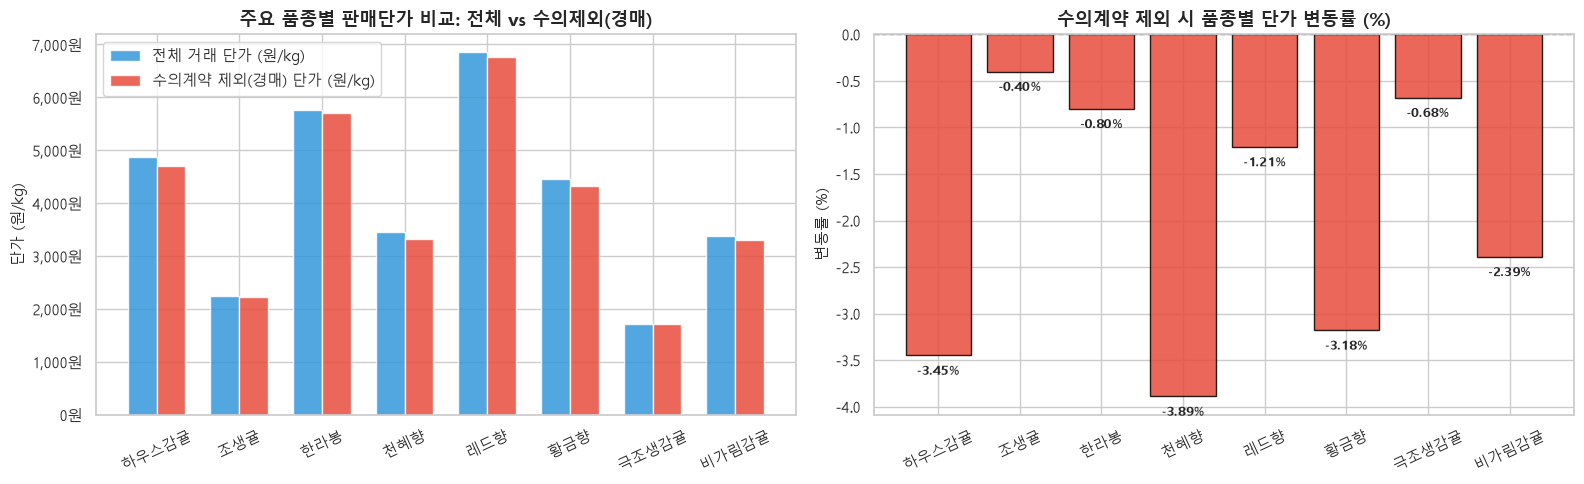

In [6]:
# 4-2) 주요 품종별 수의계약 제외 전/후 판매가격(kg당 단가) 변동 상세 비교
target_vars = ['하우스감귤', '조생귤', '한라봉', '천혜향', '레드향', '황금향', '극조생감귤', '비가림감귤']
var_diff_list = []

for var in target_vars:
    v_all = df[df['variety'] == var]
    v_auc = df[(df['variety'] == var) & (df['trd_type'] != '수의계약')]
    v_neg = df[(df['variety'] == var) & (df['trd_type'] == '수의계약')]
    
    p_all = v_all['total_price'].sum() / (v_all['volume_kg'].sum() + 1e-8)
    p_auc = v_auc['total_price'].sum() / (v_auc['volume_kg'].sum() + 1e-8)
    p_neg = v_neg['total_price'].sum() / (v_neg['volume_kg'].sum() + 1e-8) if len(v_neg) > 0 else np.nan
    
    diff = p_auc - p_all
    pct = (diff / p_all) * 100
    neg_share = (len(v_neg) / len(v_all)) * 100
    
    var_diff_list.append({
        '품종': var,
        '전체 거래건수': len(v_all),
        '수의계약 건수': len(v_neg),
        '수의 비중(%)': round(neg_share, 1),
        '전체 평균단가(원)': round(p_all, 1),
        '수의계약 단가(원)': round(p_neg, 1) if not np.isnan(p_neg) else 0,
        '수의제외(경매) 단가(원)': round(p_auc, 1),
        '단가변동액(원)': round(diff, 1),
        '변동률(%)': round(pct, 2)
    })

var_diff_df = pd.DataFrame(var_diff_list)
display(var_diff_df)

# 주요 품종별 수의계약 제외에 따른 단가 변동 시각화
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

x_idx = np.arange(len(var_diff_df))
w = 0.35
ax1.bar(x_idx - w/2, var_diff_df['전체 평균단가(원)'], width=w, label='전체 거래 단가 (원/kg)', color='#3498db', alpha=0.85)
ax1.bar(x_idx + w/2, var_diff_df['수의제외(경매) 단가(원)'], width=w, label='수의계약 제외(경매) 단가 (원/kg)', color='#e74c3c', alpha=0.85)
ax1.set_xticks(x_idx)
ax1.set_xticklabels(var_diff_df['품종'], rotation=25)
ax1.set_title("주요 품종별 판매단가 비교: 전체 vs 수의제외(경매)", fontsize=13, fontweight='bold')
ax1.set_ylabel("단가 (원/kg)", fontsize=11)
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
ax1.legend()

colors_bar = ['#e74c3c' if v < 0 else '#2ecc71' for v in var_diff_df['변동률(%)']]
bars = ax2.bar(var_diff_df['품종'], var_diff_df['변동률(%)'], color=colors_bar, alpha=0.85, edgecolor='black')
ax2.axhline(0, color='gray', linestyle='--', linewidth=1)
ax2.set_title("수의계약 제외 시 품종별 단가 변동률 (%)", fontsize=13, fontweight='bold')
ax2.set_ylabel("변동률 (%)", fontsize=11)
ax2.tick_params(axis='x', rotation=25)
for bar in bars:
    h = bar.get_height()
    va_pos = 'bottom' if h >= 0 else 'top'
    y_off = 0.1 if h >= 0 else -0.1
    ax2.annotate(f"{h:+.2f}%", (bar.get_x() + bar.get_width() / 2, h + y_off),
                 ha='center', va=va_pos, fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

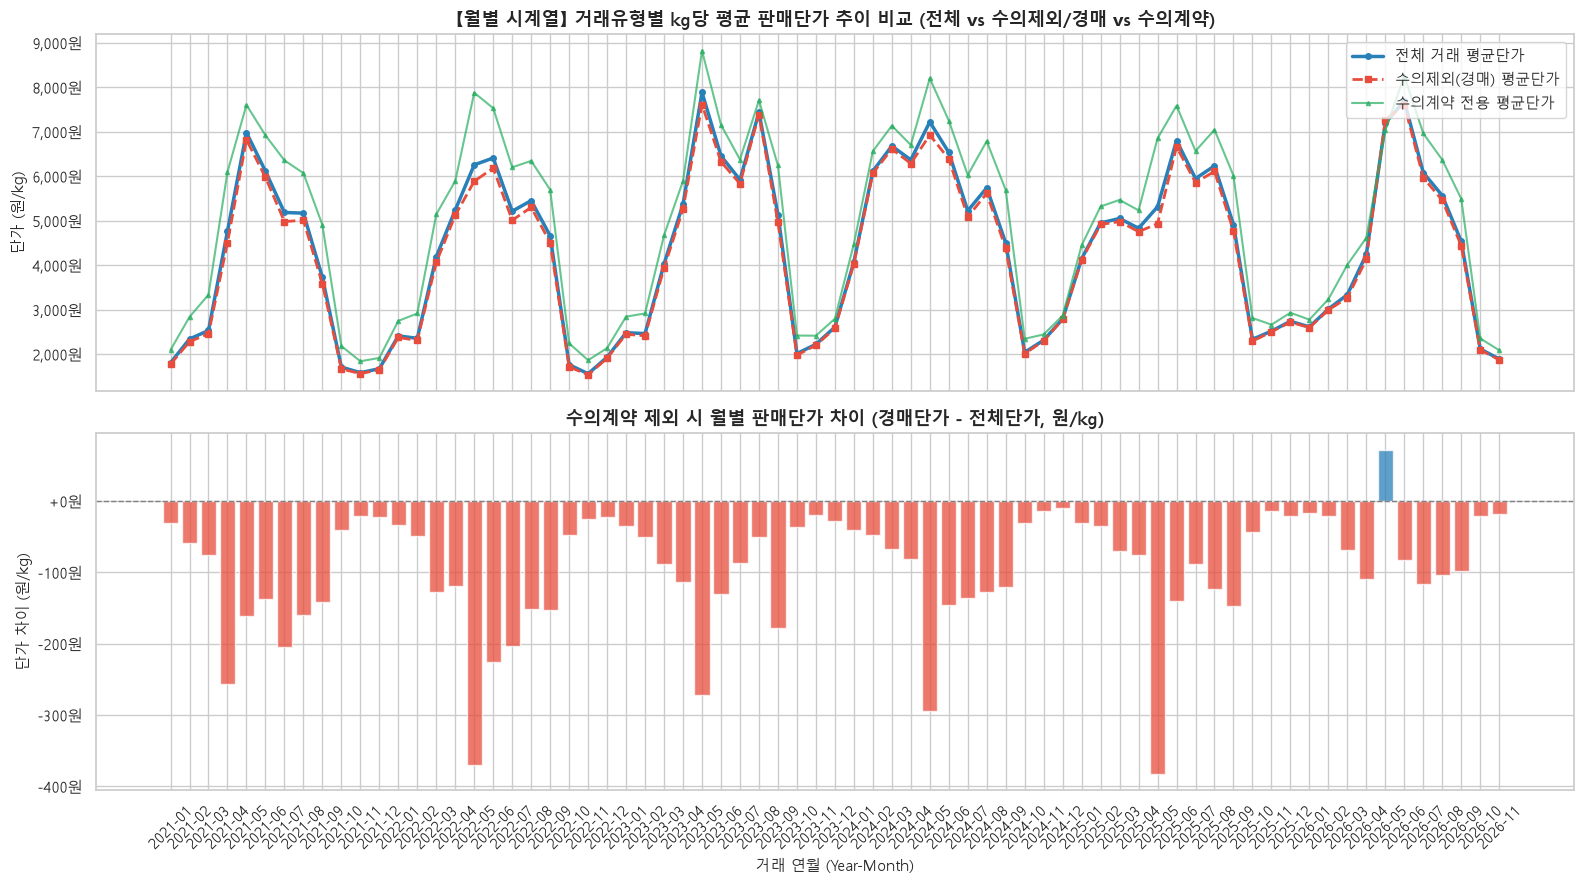


순수 경매(수의제외) 분석 데이터셋 생성 완료: 1,057,583 건


In [7]:
# 4-3) 월별 시계열 단가 추이 비교: 전체 거래 vs 수의계약 제외(경매)
monthly_all = df.groupby('year_month').agg(rev=('total_price', 'sum'), kg=('volume_kg', 'sum')).reset_index()
monthly_all['price_all'] = monthly_all['rev'] / (monthly_all['kg'] + 1e-8)

monthly_auc = df[df['trd_type'] != '수의계약'].groupby('year_month').agg(rev=('total_price', 'sum'), kg=('volume_kg', 'sum')).reset_index()
monthly_auc['price_auc'] = monthly_auc['rev'] / (monthly_auc['kg'] + 1e-8)

monthly_neg = df[df['trd_type'] == '수의계약'].groupby('year_month').agg(rev=('total_price', 'sum'), kg=('volume_kg', 'sum')).reset_index()
monthly_neg['price_neg'] = monthly_neg['rev'] / (monthly_neg['kg'] + 1e-8)

m_merged = monthly_all[['year_month', 'price_all']].merge(monthly_auc[['year_month', 'price_auc']], on='year_month')
m_merged = m_merged.merge(monthly_neg[['year_month', 'price_neg']], on='year_month', how='left')
m_merged['diff'] = m_merged['price_auc'] - m_merged['price_all']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

ax1.plot(m_merged['year_month'], m_merged['price_all'], label='전체 거래 평균단가', color='#2980b9', linewidth=2.5, marker='o', markersize=4)
ax1.plot(m_merged['year_month'], m_merged['price_auc'], label='수의제외(경매) 평균단가', color='#e74c3c', linewidth=2, linestyle='--', marker='s', markersize=4)
ax1.plot(m_merged['year_month'], m_merged['price_neg'], label='수의계약 전용 평균단가', color='#27ae60', linewidth=1.5, alpha=0.7, marker='^', markersize=3)
ax1.set_title("【월별 시계열】 거래유형별 kg당 평균 판매단가 추이 비교 (전체 vs 수의제외/경매 vs 수의계약)", fontsize=13, fontweight='bold')
ax1.set_ylabel("단가 (원/kg)", fontsize=11)
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
ax1.legend(loc='upper right', frameon=True)

ax2.bar(m_merged['year_month'], m_merged['diff'], color=np.where(m_merged['diff'] < 0, '#e74c3c', '#2980b9'), alpha=0.75)
ax2.axhline(0, color='gray', linestyle='--', linewidth=1)
ax2.set_title("수의계약 제외 시 월별 판매단가 차이 (경매단가 - 전체단가, 원/kg)", fontsize=13, fontweight='bold')
ax2.set_xlabel("거래 연월 (Year-Month)", fontsize=11)
ax2.set_ylabel("단가 차이 (원/kg)", fontsize=11)
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):+,}원"))
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

df_auction = df[df['trd_type'] != '수의계약'].copy().reset_index(drop=True)
print(f"\n순수 경매(수의제외) 분석 데이터셋 생성 완료: {len(df_auction):,} 건")

## 5. [날짜별] 판매수량 및 판매가격 분석 및 시각화
- **일별 전체 물량 & kg당 평균 단가 시계열 추이** (2축 Dual-Axis 차트, 7일 이동평균 추세선)
- **월별 누적 판매물량 및 월평균 단가 추이** (계절성 및 출하 사이클 파악)
- **연도별/월별 물량 히트맵**

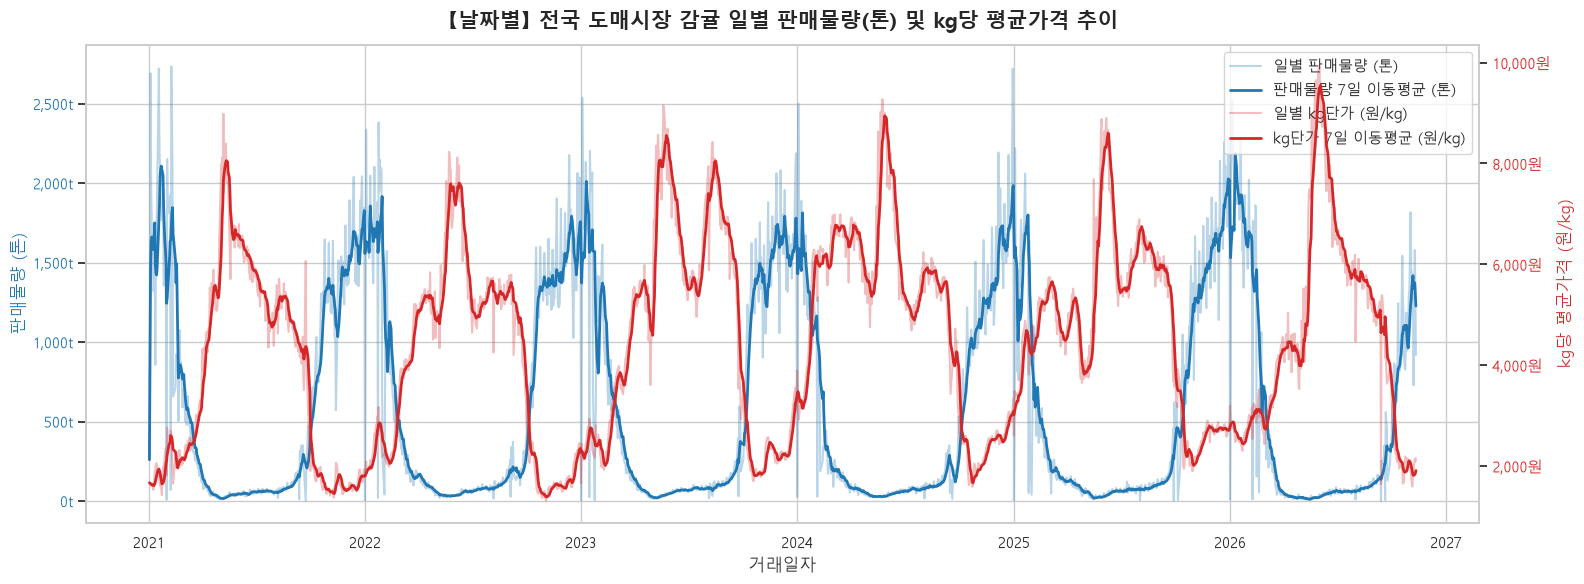

In [8]:
# 1) 일별 집계
daily_agg = df.groupby('date').agg(
    daily_volume_ton=('volume_kg', lambda x: x.sum() / 1000.0),
    daily_boxes=('box_qty', 'sum'),
    daily_total_price=('total_price', 'sum'),
    daily_volume_kg=('volume_kg', 'sum')
).reset_index()
daily_agg['daily_avg_price_kg'] = daily_agg['daily_total_price'] / (daily_agg['daily_volume_kg'] + 1e-8)

daily_agg['vol_ton_ma7'] = daily_agg['daily_volume_ton'].rolling(7, min_periods=1).mean()
daily_agg['price_kg_ma7'] = daily_agg['daily_avg_price_kg'].rolling(7, min_periods=1).mean()

fig, ax1 = plt.subplots(figsize=(16, 6))

color_vol = '#1f77b4'
color_price = '#d62728'

ax1.set_title("【날짜별】 전국 도매시장 감귤 일별 판매물량(톤) 및 kg당 평균가격 추이", fontsize=15, pad=12, fontweight='bold')
ax1.plot(daily_agg['date'], daily_agg['daily_volume_ton'], color=color_vol, alpha=0.3, label='일별 판매물량 (톤)')
ax1.plot(daily_agg['date'], daily_agg['vol_ton_ma7'], color=color_vol, linewidth=2, label='판매물량 7일 이동평균 (톤)')
ax1.set_xlabel('거래일자', fontsize=12)
ax1.set_ylabel('판매물량 (톤)', color=color_vol, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color_vol)
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))

ax2 = ax1.twinx()
ax2.plot(daily_agg['date'], daily_agg['daily_avg_price_kg'], color=color_price, alpha=0.3, label='일별 kg단가 (원/kg)')
ax2.plot(daily_agg['date'], daily_agg['price_kg_ma7'], color=color_price, linewidth=2, label='kg단가 7일 이동평균 (원/kg)')
ax2.set_ylabel('kg당 평균가격 (원/kg)', color=color_price, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color_price)
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
ax2.grid(False)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

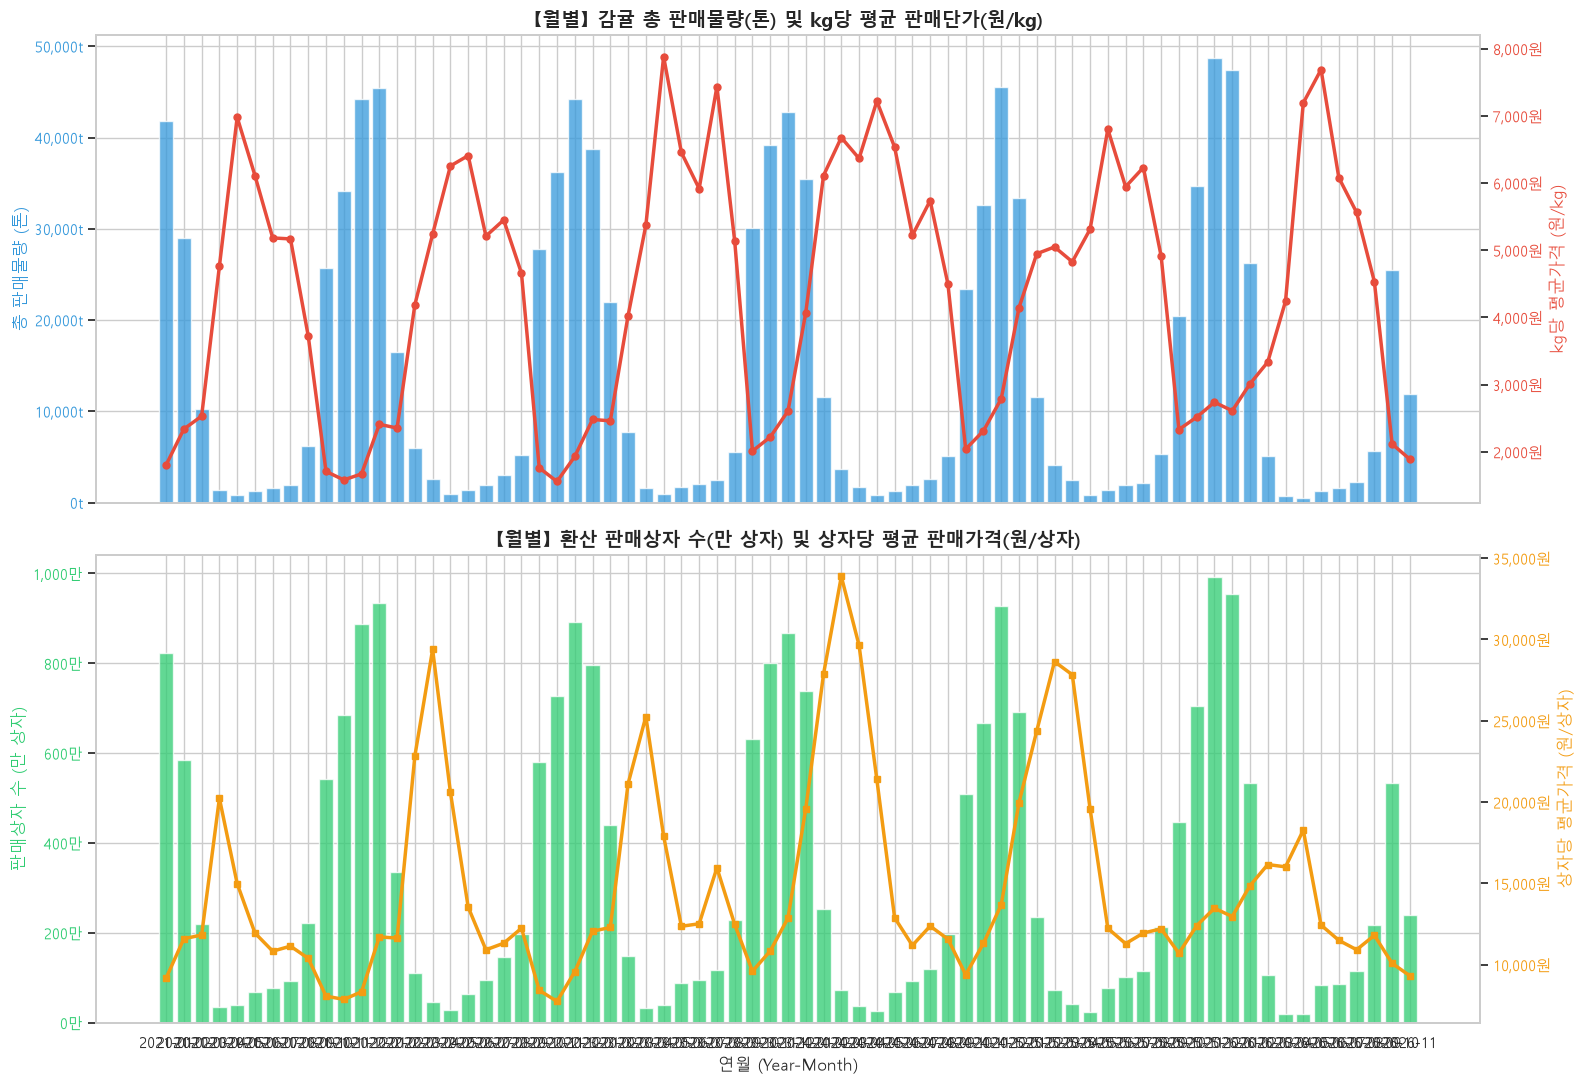

In [9]:
# 2) 월별 집계 및 복합 차트 (월별 판매수량 막대 + 월별 평균단가 꺾은선)
monthly_agg = df.groupby('year_month').agg(
    total_volume_ton=('volume_kg', lambda x: x.sum() / 1000.0),
    total_boxes=('box_qty', 'sum'),
    total_price=('total_price', 'sum'),
    total_volume_kg=('volume_kg', 'sum')
).reset_index()
monthly_agg['avg_unit_price_kg'] = monthly_agg['total_price'] / (monthly_agg['total_volume_kg'] + 1e-8)
monthly_agg['avg_box_price'] = monthly_agg['total_price'] / (monthly_agg['total_boxes'] + 1e-8)

fig, (ax1, ax3) = plt.subplots(2, 1, figsize=(16, 11), sharex=True)

color_bar = '#3498db'
color_line = '#e74c3c'

ax1.bar(monthly_agg['year_month'], monthly_agg['total_volume_ton'], color=color_bar, alpha=0.75, label='월별 총 판매물량 (톤)')
ax1.set_ylabel('총 판매물량 (톤)', color=color_bar, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color_bar)
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
ax1.set_title("【월별】 감귤 총 판매물량(톤) 및 kg당 평균 판매단가(원/kg)", fontsize=14, fontweight='bold')

ax2 = ax1.twinx()
ax2.plot(monthly_agg['year_month'], monthly_agg['avg_unit_price_kg'], color=color_line, marker='o', linewidth=2.5, markersize=5, label='월평균 kg당 단가 (원/kg)')
ax2.set_ylabel('kg당 평균가격 (원/kg)', color=color_line, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color_line)
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
ax2.grid(False)

color_box_bar = '#2ecc71'
color_box_line = '#f39c12'

ax3.bar(monthly_agg['year_month'], monthly_agg['total_boxes'] / 10000, color=color_box_bar, alpha=0.75, label='월별 환산 판매상자 수 (만 상자)')
ax3.set_ylabel('판매상자 수 (만 상자)', color=color_box_bar, fontsize=12)
ax3.tick_params(axis='y', labelcolor=color_box_bar)
ax3.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}만"))
ax3.set_title("【월별】 환산 판매상자 수(만 상자) 및 상자당 평균 판매가격(원/상자)", fontsize=14, fontweight='bold')
ax3.set_xlabel('연월 (Year-Month)', fontsize=12)
plt.xticks(rotation=45)

ax4 = ax3.twinx()
ax4.plot(monthly_agg['year_month'], monthly_agg['avg_box_price'], color=color_box_line, marker='s', linewidth=2.5, markersize=5, label='월평균 상자당 가격 (원/상자)')
ax4.set_ylabel('상자당 평균가격 (원/상자)', color=color_box_line, fontsize=12)
ax4.tick_params(axis='y', labelcolor=color_box_line)
ax4.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
ax4.grid(False)

plt.tight_layout()
plt.show()

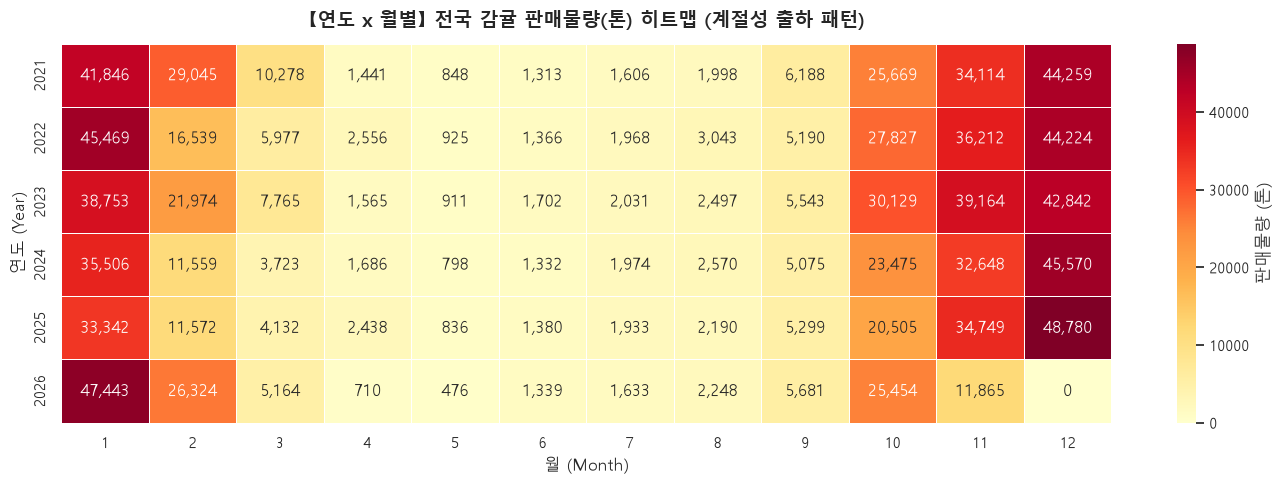

In [10]:
# 3) 연도별 x 월별 판매물량 히트맵 (출하 계절성 패턴 시각화)
pivot_vol = df.pivot_table(index='year', columns='month', values='volume_kg', aggfunc=lambda x: x.sum() / 1000.0).fillna(0)

plt.figure(figsize=(14, 5))
sns.heatmap(pivot_vol, cmap='YlOrRd', annot=True, fmt=',.0f', cbar_kws={'label': '판매물량 (톤)'}, linewidths=0.5)
plt.title("【연도 x 월별】 전국 감귤 판매물량(톤) 히트맵 (계절성 출하 패턴)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("월 (Month)", fontsize=12)
plt.ylabel("연도 (Year)", fontsize=12)
plt.tight_layout()
plt.show()

## 6. [등급별] 판매수량 및 판매가격 분석 및 시각화
- 등급(`특`, `상`, `중`, `하`, `등외`, `무등급/미지정`)별 총 판매수량(kg 및 상자수)
- 등급별 평균 판매가격(kg당 단가 및 상자당 가격) 비교
- 등급별 판매가격 분포(Boxplot) 시각화

In [11]:
# 1) 등급별 판매수량 및 평균단가 집계
grade_order = ['특', '상', '중', '하', '등외', '무등급/미지정']
avail_grades = [g for g in grade_order if g in df['grade'].values]
other_grades = [g for g in df['grade'].unique() if g not in grade_order]
all_grade_order = avail_grades + other_grades

grade_agg = df.groupby('grade').agg(
    total_volume_ton=('volume_kg', lambda x: x.sum() / 1000.0),
    total_boxes=('box_qty', 'sum'),
    total_price=('total_price', 'sum'),
    total_volume_kg=('volume_kg', 'sum'),
    box_price_mean=('box_price', 'mean'),
    count=('volume_kg', 'count')
).reindex(all_grade_order).dropna(subset=['count']).reset_index()

grade_agg['avg_unit_price_kg'] = grade_agg['total_price'] / (grade_agg['total_volume_kg'] + 1e-8)
grade_agg['share_pct'] = (grade_agg['total_volume_kg'] / grade_agg['total_volume_kg'].sum()) * 100

display(grade_agg[['grade', 'count', 'total_volume_ton', 'share_pct', 'total_boxes', 'avg_unit_price_kg', 'box_price_mean']]
        .rename(columns={
            'grade': '등급',
            'count': '거래건수',
            'total_volume_ton': '총 판매물량(톤)',
            'share_pct': '물량 비중(%)',
            'total_boxes': '환산상자수',
            'avg_unit_price_kg': 'kg당 평균단가(원)',
            'box_price_mean': '상자당 평균가격(원)'
        }))

,등급,거래건수,총 판매물량(톤),물량 비중(%),환산상자수,kg당 평균단가(원),상자당 평균가격(원)
0,특,885423,704091.66220,67.300903,1.574925e+08,2839.692521,16783.688951
1,상,66512,63659.82813,6.084952,1.405432e+07,2621.122528,15084.413580
2,중,86027,49015.82945,4.685199,1.039305e+07,2450.793955,11665.730797
3,하,30583,15074.07447,1.440862,3.142043e+06,2402.600010,13191.117695
4,등외,39216,50281.76081,4.806204,1.050003e+07,2631.631327,16052.961738
5,무등급/미지정,101236,149304.90912,14.271374,3.169104e+07,2445.651618,14465.536897
6,8등,3425,536.54260,0.051286,1.204290e+05,4810.888865,20885.052671
7,7등,7444,1849.64270,0.176799,4.734220e+05,3519.615713,16536.804130
8,6등,6942,4116.87720,0.393513,8.327870e+05,1977.415953,14409.214985
9,5등,15515,6337.13405,0.605738,1.314152e+06,2278.394438,13564.173254


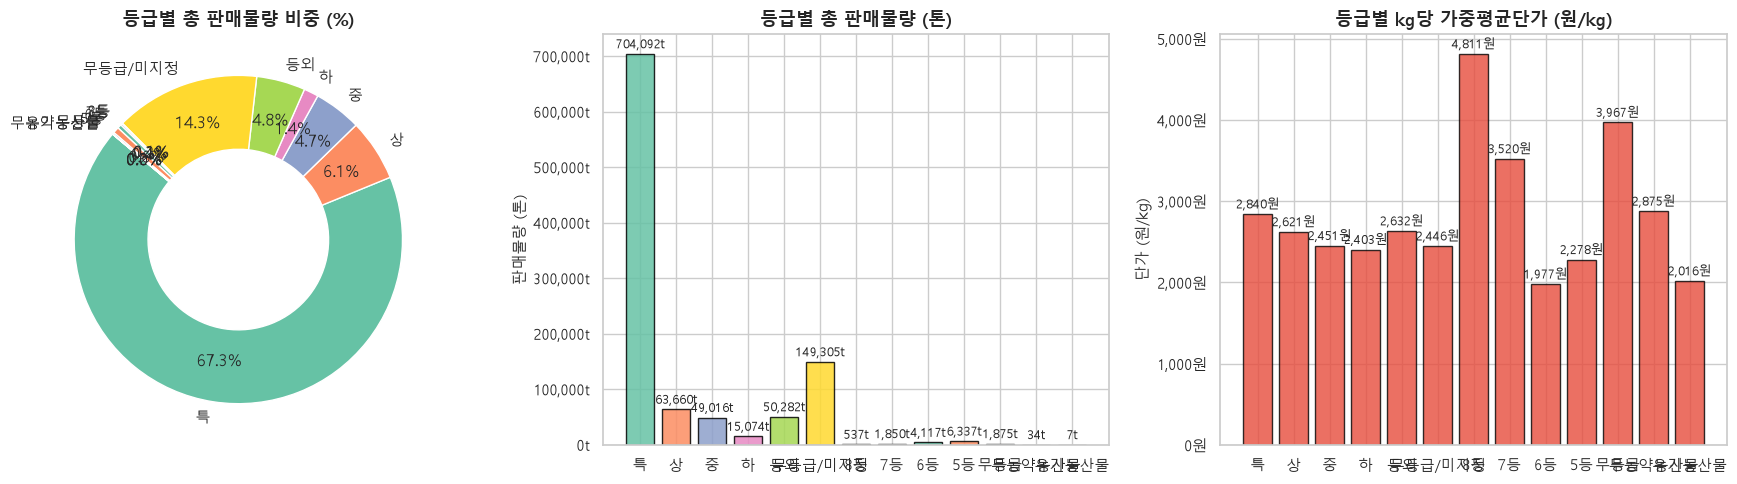

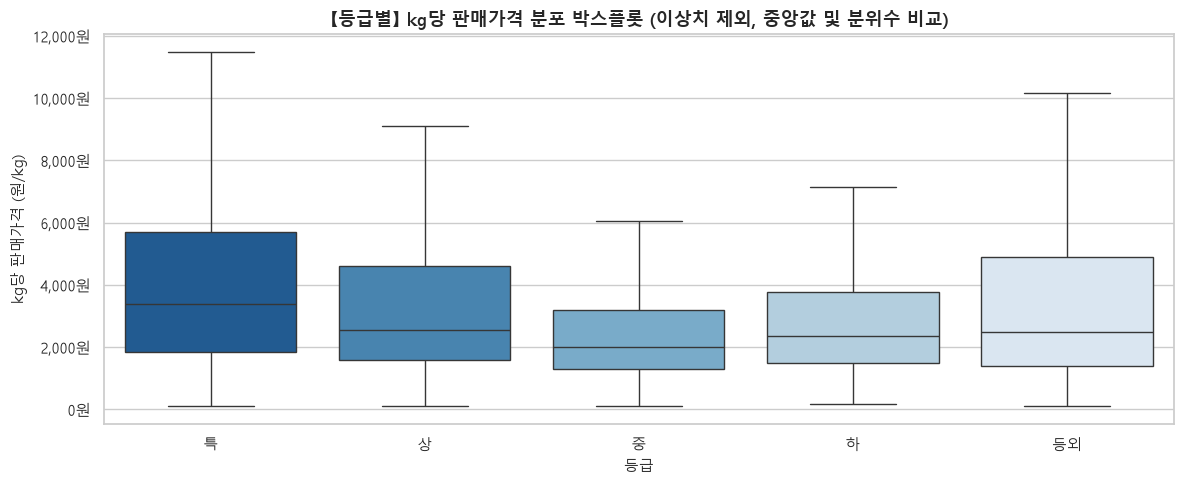

In [12]:
# 2) 등급별 물량 비중 및 평균 단가 비교 그래프
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

colors_grade = sns.color_palette('Set2', len(grade_agg))
axes[0].pie(grade_agg['total_volume_ton'], labels=grade_agg['grade'], autopct='%1.1f%%',
            startangle=140, colors=colors_grade, pctdistance=0.75,
            wedgeprops=dict(width=0.45, edgecolor='w'))
axes[0].set_title("등급별 총 판매물량 비중 (%)", fontsize=13, fontweight='bold')

bars = axes[1].bar(grade_agg['grade'], grade_agg['total_volume_ton'], color=colors_grade, edgecolor='black', alpha=0.85)
axes[1].set_title("등급별 총 판매물량 (톤)", fontsize=13, fontweight='bold')
axes[1].set_ylabel("판매물량 (톤)", fontsize=11)
axes[1].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
for bar in bars:
    h = bar.get_height()
    axes[1].annotate(f"{h:,.0f}t", (bar.get_x() + bar.get_width() / 2, h),
                     textcoords="offset points", xytext=(0, 4), ha='center', fontsize=9)

bars_p = axes[2].bar(grade_agg['grade'], grade_agg['avg_unit_price_kg'], color='#e74c3c', edgecolor='black', alpha=0.8)
axes[2].set_title("등급별 kg당 가중평균단가 (원/kg)", fontsize=13, fontweight='bold')
axes[2].set_ylabel("단가 (원/kg)", fontsize=11)
axes[2].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
for bar in bars_p:
    h = bar.get_height()
    axes[2].annotate(f"{h:,.0f}원", (bar.get_x() + bar.get_width() / 2, h),
                     textcoords="offset points", xytext=(0, 4), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

main_grades = [g for g in ['특', '상', '중', '하', '등외'] if g in df['grade'].values]
sub_grade_df = df[df['grade'].isin(main_grades)].copy()

plt.figure(figsize=(12, 5))
sns.boxplot(data=sub_grade_df, x='grade', y='unit_price_kg', order=main_grades, palette='Blues_r', showfliers=False)
plt.title("【등급별】 kg당 판매가격 분포 박스플롯 (이상치 제외, 중앙값 및 분위수 비교)", fontsize=13, fontweight='bold')
plt.xlabel("등급", fontsize=11)
plt.ylabel("kg당 판매가격 (원/kg)", fontsize=11)
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
plt.tight_layout()
plt.show()

## 7. [종류별 (품종별)] 판매수량 및 판매가격 분석 및 시각화
- 감귤 종류(하우스감귤, 조생귤, 한라봉, 천혜향, 레드향, 황금향, 극조생감귤, 비가림감귤 등)별 판매수량 및 순위
- 품종별 kg당 평균 판매가격 비교 (만감류 vs 온주밀감 프리미엄 비교)
- 주요 4대 대표 품종(하우스감귤, 조생귤, 한라봉, 천혜향)의 월별 판매물량 및 단가 추이

In [13]:
# 1) 품종별 집계
variety_agg = df.groupby('variety').agg(
    total_volume_ton=('volume_kg', lambda x: x.sum() / 1000.0),
    total_boxes=('box_qty', 'sum'),
    total_price=('total_price', 'sum'),
    total_volume_kg=('volume_kg', 'sum'),
    box_price_mean=('box_price', 'mean'),
    count=('volume_kg', 'count')
).reset_index()

variety_agg['avg_unit_price_kg'] = variety_agg['total_price'] / (variety_agg['total_volume_kg'] + 1e-8)
variety_agg['share_pct'] = (variety_agg['total_volume_kg'] / variety_agg['total_volume_kg'].sum()) * 100

variety_agg_vol = variety_agg.sort_values('total_volume_ton', ascending=False).reset_index(drop=True)

display(variety_agg_vol[['variety', 'count', 'total_volume_ton', 'share_pct', 'total_boxes', 'avg_unit_price_kg', 'box_price_mean']]
        .rename(columns={
            'variety': '품종(종류)',
            'count': '거래건수',
            'total_volume_ton': '총 판매물량(톤)',
            'share_pct': '물량 비중(%)',
            'total_boxes': '환산상자수',
            'avg_unit_price_kg': 'kg당 평균단가(원)',
            'box_price_mean': '상자당 평균가격(원)'
        }))

,품종(종류),거래건수,총 판매물량(톤),물량 비중(%),환산상자수,kg당 평균단가(원),상자당 평균가격(원)
0,조생귤,316478,500214.22010,47.813190,9.942473e+07,2233.197870,10764.122022
1,기타,160751,183568.94547,17.546516,3.759603e+07,2169.615693,11866.637815
2,극조생감귤,92528,97957.61731,9.363321,1.939160e+07,1720.572268,8029.063964
3,하우스감귤,322086,89987.56901,8.601500,3.569970e+07,4869.481118,18673.942212
4,한라봉,132842,51787.53808,4.950134,1.070572e+07,5753.033770,29535.006159
5,비가림감귤,63145,36655.72555,3.503753,8.029755e+06,3380.764866,15139.422961
6,감귤(일반),10123,24069.72094,2.300715,5.107165e+06,2478.266100,12983.550942
7,레드향,52851,17002.31315,1.625173,4.224867e+06,6848.458823,27627.379454
8,타이벡감귤,19696,16247.42540,1.553017,3.308314e+06,3127.175261,14447.200252
9,천혜향,48396,11402.11085,1.089876,3.266164e+06,3445.604185,12890.688460


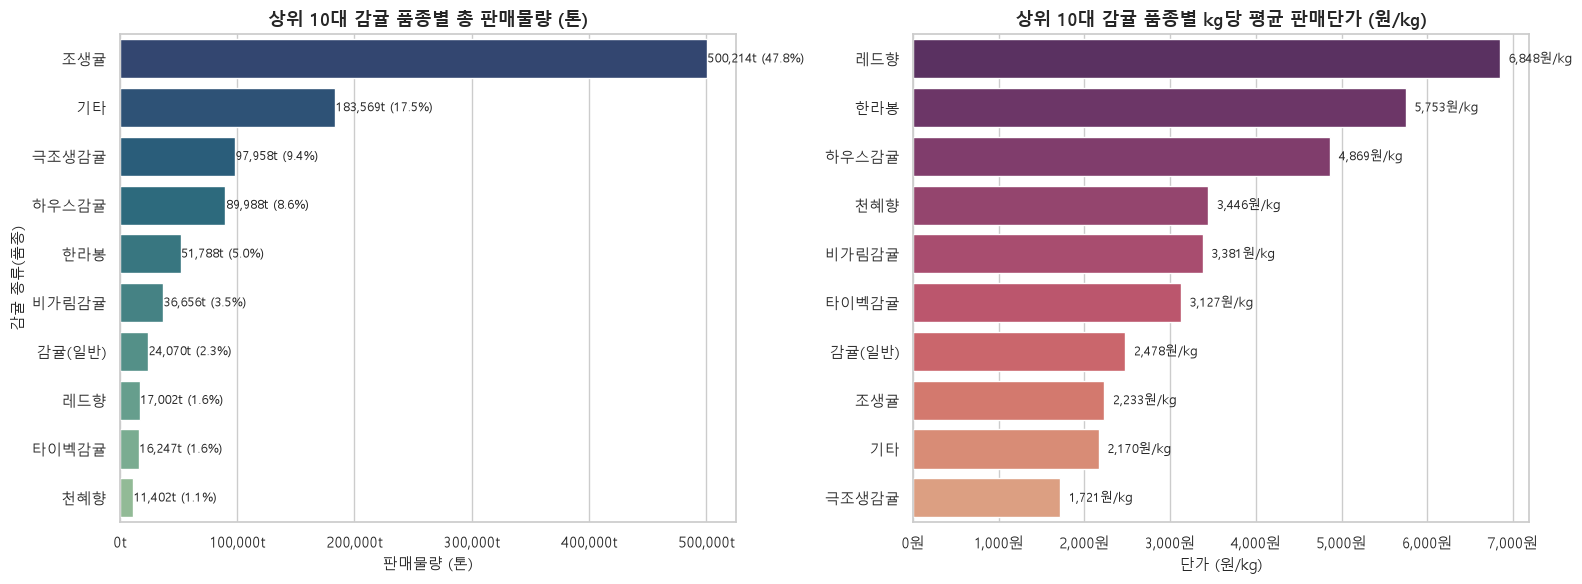

In [14]:
# 2) 품종별 판매물량 및 평균 판매가격 비교 차트 (상위 10대 품종)
top_varieties_df = variety_agg_vol.head(10)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=top_varieties_df, y='variety', x='total_volume_ton', ax=ax1, palette='crest_r')
ax1.set_title("상위 10대 감귤 품종별 총 판매물량 (톤)", fontsize=13, fontweight='bold')
ax1.set_xlabel("판매물량 (톤)", fontsize=11)
ax1.set_ylabel("감귤 종류(품종)", fontsize=11)
ax1.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
for i, v in enumerate(top_varieties_df['total_volume_ton']):
    ax1.text(v + 500, i, f"{v:,.0f}t ({top_varieties_df['share_pct'].iloc[i]:.1f}%)", va='center', fontsize=9)

top_varieties_price_df = top_varieties_df.sort_values('avg_unit_price_kg', ascending=False)
sns.barplot(data=top_varieties_price_df, y='variety', x='avg_unit_price_kg', ax=ax2, palette='flare_r')
ax2.set_title("상위 10대 감귤 품종별 kg당 평균 판매단가 (원/kg)", fontsize=13, fontweight='bold')
ax2.set_xlabel("단가 (원/kg)", fontsize=11)
ax2.set_ylabel("", fontsize=11)
ax2.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
for i, v in enumerate(top_varieties_price_df['avg_unit_price_kg']):
    ax2.text(v + 100, i, f"{v:,.0f}원/kg", va='center', fontsize=9)

plt.tight_layout()
plt.show()

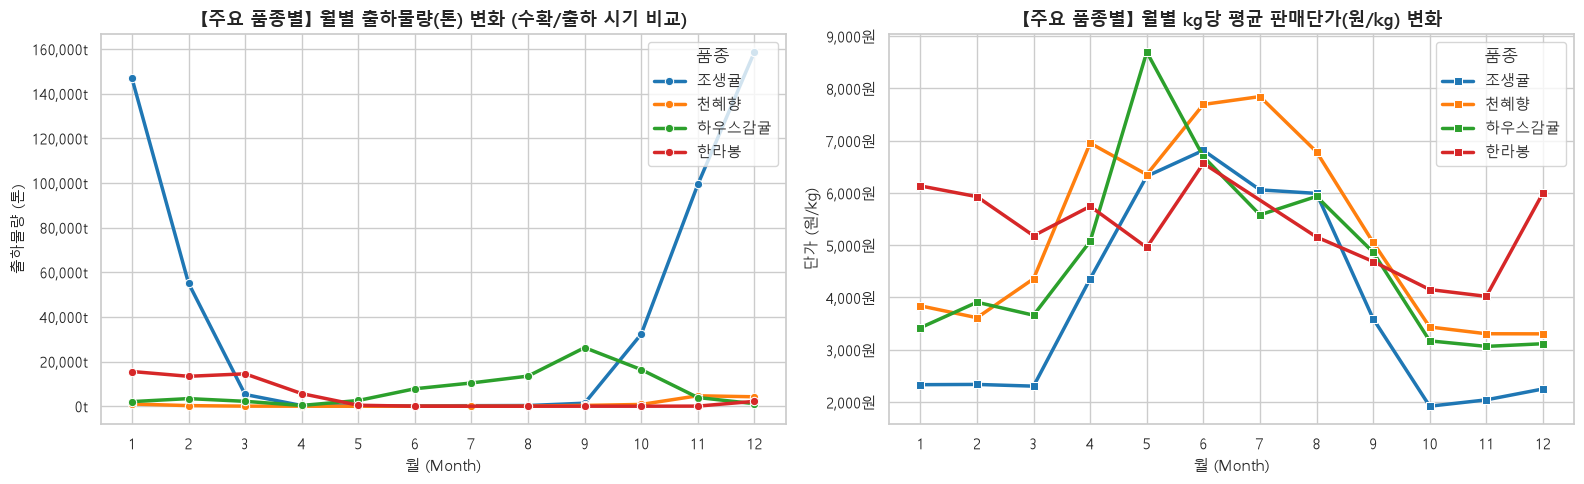

In [15]:
# 3) 주요 4대 대표 품종(하우스감귤, 조생귤, 한라봉, 천혜향)의 월별 물량 및 단가 동적 비교
core_vars = ['하우스감귤', '조생귤', '한라봉', '천혜향']
core_df = df[df['variety'].isin(core_vars)].copy()

var_month_agg = core_df.groupby(['month', 'variety']).agg(
    vol_ton=('volume_kg', lambda x: x.sum() / 1000.0),
    total_price=('total_price', 'sum'),
    total_kg=('volume_kg', 'sum')
).reset_index()
var_month_agg['avg_price_kg'] = var_month_agg['total_price'] / (var_month_agg['total_kg'] + 1e-8)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

sns.lineplot(data=var_month_agg, x='month', y='vol_ton', hue='variety', marker='o', linewidth=2.5, ax=ax1, palette='tab10')
ax1.set_title("【주요 품종별】 월별 출하물량(톤) 변화 (수확/출하 시기 비교)", fontsize=13, fontweight='bold')
ax1.set_xlabel("월 (Month)", fontsize=11)
ax1.set_ylabel("출하물량 (톤)", fontsize=11)
ax1.set_xticks(range(1, 13))
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
ax1.legend(title='품종', loc='upper right')

sns.lineplot(data=var_month_agg, x='month', y='avg_price_kg', hue='variety', marker='s', linewidth=2.5, ax=ax2, palette='tab10')
ax2.set_title("【주요 품종별】 월별 kg당 평균 판매단가(원/kg) 변화", fontsize=13, fontweight='bold')
ax2.set_xlabel("월 (Month)", fontsize=11)
ax2.set_ylabel("단가 (원/kg)", fontsize=11)
ax2.set_xticks(range(1, 13))
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
ax2.legend(title='품종', loc='upper right')

plt.tight_layout()
plt.show()

## 8. [크기별] 판매수량 및 판매가격 분석 (품종별 세부 분류 포함)
- **크기 규격 정렬 기준**: 사용자가 지정한 표준 크기 순서 (`50내` -> `45내` -> `40내` -> `35내` -> `소` -> `중` -> `대` -> `특대`)로 정리하여 분석합니다.
- **8-1) 전체 감귤 크기 규격별 분석**: 지정 크기 규격 순서별 총 판매물량(톤), 물량 비중(%), kg당 평균단가(원/kg)
- **8-2) [품종별 세부 분류]**: 감귤 품종(하우스감귤, 조생귤, 천혜향, 황금향, 레드향)마다 동일한 표준 크기 순서(`50내, 45내, 40내, 35내, 소, 중, 대, 특대`)로 세부 분류하여 판매물량과 판매단가를 비교 분석합니다.

,크기 규격,거래건수,총 판매물량(톤),물량 비중(%),환산상자수,kg당 평균단가(원),상자당 평균가격(원)
0,50내,61029,24267.13884,11.252982,5111011.0,3694.800353,18506.150530
1,45내,31549,5385.66460,2.497401,1336579.0,5343.626606,22483.113424
2,40내,59320,21180.77792,9.821797,4844275.0,4043.286497,19140.035060
3,35내,32500,5104.33190,2.366944,1465942.0,5199.431908,19209.911802
4,소,36247,61215.07424,28.386211,12304240.0,2700.774778,13697.852701
5,중,24644,33776.82020,15.662742,6770439.0,2439.849686,12667.397891
6,대,27636,29410.19950,13.637885,5869283.0,2016.105508,9863.933673
7,특대,39771,35310.73710,16.374039,7048930.0,1958.450284,11529.565130


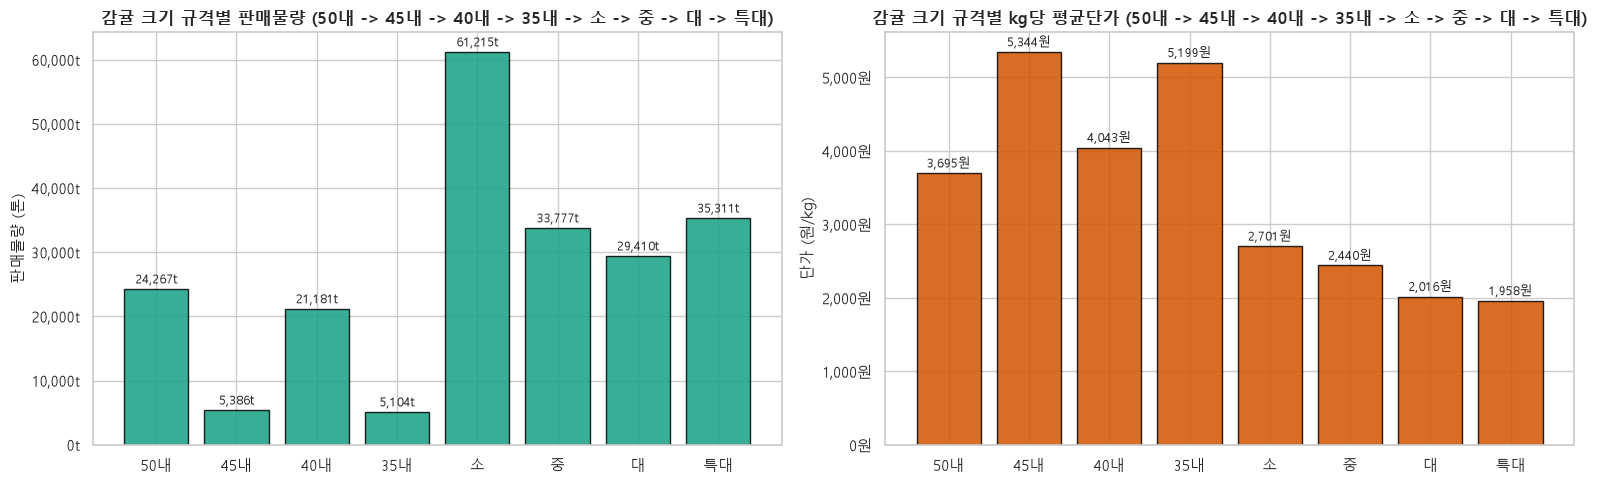

In [16]:
# 8-1) 전체 크기 규격별 집계 (지정 순서: 50내, 45내, 40내, 35내, 소, 중, 대, 특대)
size_order = ['50내', '45내', '40내', '35내', '소', '중', '대', '특대']

size_agg = df[df['size'].isin(size_order)].groupby('size').agg(
    total_volume_ton=('volume_kg', lambda x: x.sum() / 1000.0),
    total_boxes=('box_qty', 'sum'),
    total_price=('total_price', 'sum'),
    total_volume_kg=('volume_kg', 'sum'),
    box_price_mean=('box_price', 'mean'),
    count=('volume_kg', 'count')
).reindex(size_order).reset_index()

size_agg['avg_unit_price_kg'] = size_agg['total_price'] / (size_agg['total_volume_kg'] + 1e-8)
size_agg['share_pct'] = (size_agg['total_volume_kg'] / size_agg['total_volume_kg'].sum()) * 100

display(size_agg[['size', 'count', 'total_volume_ton', 'share_pct', 'total_boxes', 'avg_unit_price_kg', 'box_price_mean']]
        .rename(columns={
            'size': '크기 규격',
            'count': '거래건수',
            'total_volume_ton': '총 판매물량(톤)',
            'share_pct': '물량 비중(%)',
            'total_boxes': '환산상자수',
            'avg_unit_price_kg': 'kg당 평균단가(원)',
            'box_price_mean': '상자당 평균가격(원)'
        }))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
bars1 = ax1.bar(size_agg['size'], size_agg['total_volume_ton'], color='#16a085', edgecolor='black', alpha=0.85)
ax1.set_title("감귤 크기 규격별 판매물량 (50내 -> 45내 -> 40내 -> 35내 -> 소 -> 중 -> 대 -> 특대)", fontsize=12, fontweight='bold')
ax1.set_ylabel("판매물량 (톤)", fontsize=11)
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
for bar in bars1:
    h = bar.get_height()
    ax1.annotate(f"{h:,.0f}t", (bar.get_x() + bar.get_width() / 2, h), textcoords="offset points", xytext=(0, 4), ha='center', fontsize=9)

bars2 = ax2.bar(size_agg['size'], size_agg['avg_unit_price_kg'], color='#d35400', edgecolor='black', alpha=0.85)
ax2.set_title("감귤 크기 규격별 kg당 평균단가 (50내 -> 45내 -> 40내 -> 35내 -> 소 -> 중 -> 대 -> 특대)", fontsize=12, fontweight='bold')
ax2.set_ylabel("단가 (원/kg)", fontsize=11)
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
for bar in bars2:
    h = bar.get_height()
    ax2.annotate(f"{h:,.0f}원", (bar.get_x() + bar.get_width() / 2, h), textcoords="offset points", xytext=(0, 4), ha='center', fontsize=9)
plt.tight_layout()
plt.show()

In [17]:
# 8-2) 【품종별 세부 크기 분류】 주요 5대 품종별 크기 규격별 집계 (지정 순서 적용)
target_varieties = ['하우스감귤', '조생귤', '한라봉', '천혜향', '레드향']
size_order = ['50내', '45내', '40내', '35내', '소', '중', '대', '특대']
variety_size_tables = []

for var in target_varieties:
    sub_df = df[(df['variety'] == var) & (df['size'].isin(size_order))]
    agg = sub_df.groupby('size').agg(
        거래건수=('volume_kg', 'count'),
        총판매물량_톤=('volume_kg', lambda x: x.sum() / 1000.0),
        총판매금액_백만원=('total_price', lambda x: x.sum() / 1e6),
        환산상자수=('box_qty', 'sum'),
        total_kg=('volume_kg', 'sum'),
        total_rev=('total_price', 'sum')
    )
    agg['kg당평균단가_원'] = (agg['total_rev'] / (agg['total_kg'] + 1e-8)).round(0)
    agg['물량비중_pct'] = ((agg['total_kg'] / agg['total_kg'].sum()) * 100).round(1)
    
    # 지정 순서대로 정렬 (존재하는 항목만 필터)
    var_size = agg.reindex(size_order).dropna(subset=['거래건수']).reset_index()
    var_size.insert(0, '품종', var)
    variety_size_tables.append(var_size)

variety_size_summary_df = pd.concat(variety_size_tables, ignore_index=True)
display(variety_size_summary_df[['품종', 'size', '거래건수', '총판매물량_톤', '물량비중_pct', 'kg당평균단가_원', '환산상자수']]
        .rename(columns={'size': '크기 규격'}))

,품종,크기 규격,거래건수,총판매물량_톤,물량비중_pct,kg당평균단가_원,환산상자수
0,하우스감귤,50내,23623,5516.88774,18.9,5767.0,1778513.0
1,하우스감귤,45내,25876,3915.57280,13.4,5465.0,1142259.0
2,하우스감귤,40내,33448,7114.68240,24.4,5765.0,2237417.0
3,하우스감귤,35내,27544,4182.66140,14.3,5404.0,1283897.0
4,하우스감귤,소,5280,4344.08930,14.9,4413.0,922725.0
5,하우스감귤,중,2973,1217.59470,4.2,3866.0,275078.0
6,하우스감귤,대,3267,890.52090,3.0,3217.0,189658.0
7,하우스감귤,특대,6209,2021.75100,6.9,4831.0,462290.0
8,조생귤,50내,14843,7828.41200,11.0,2222.0,1537750.0
9,조생귤,45내,298,46.53400,0.1,4272.0,13224.0


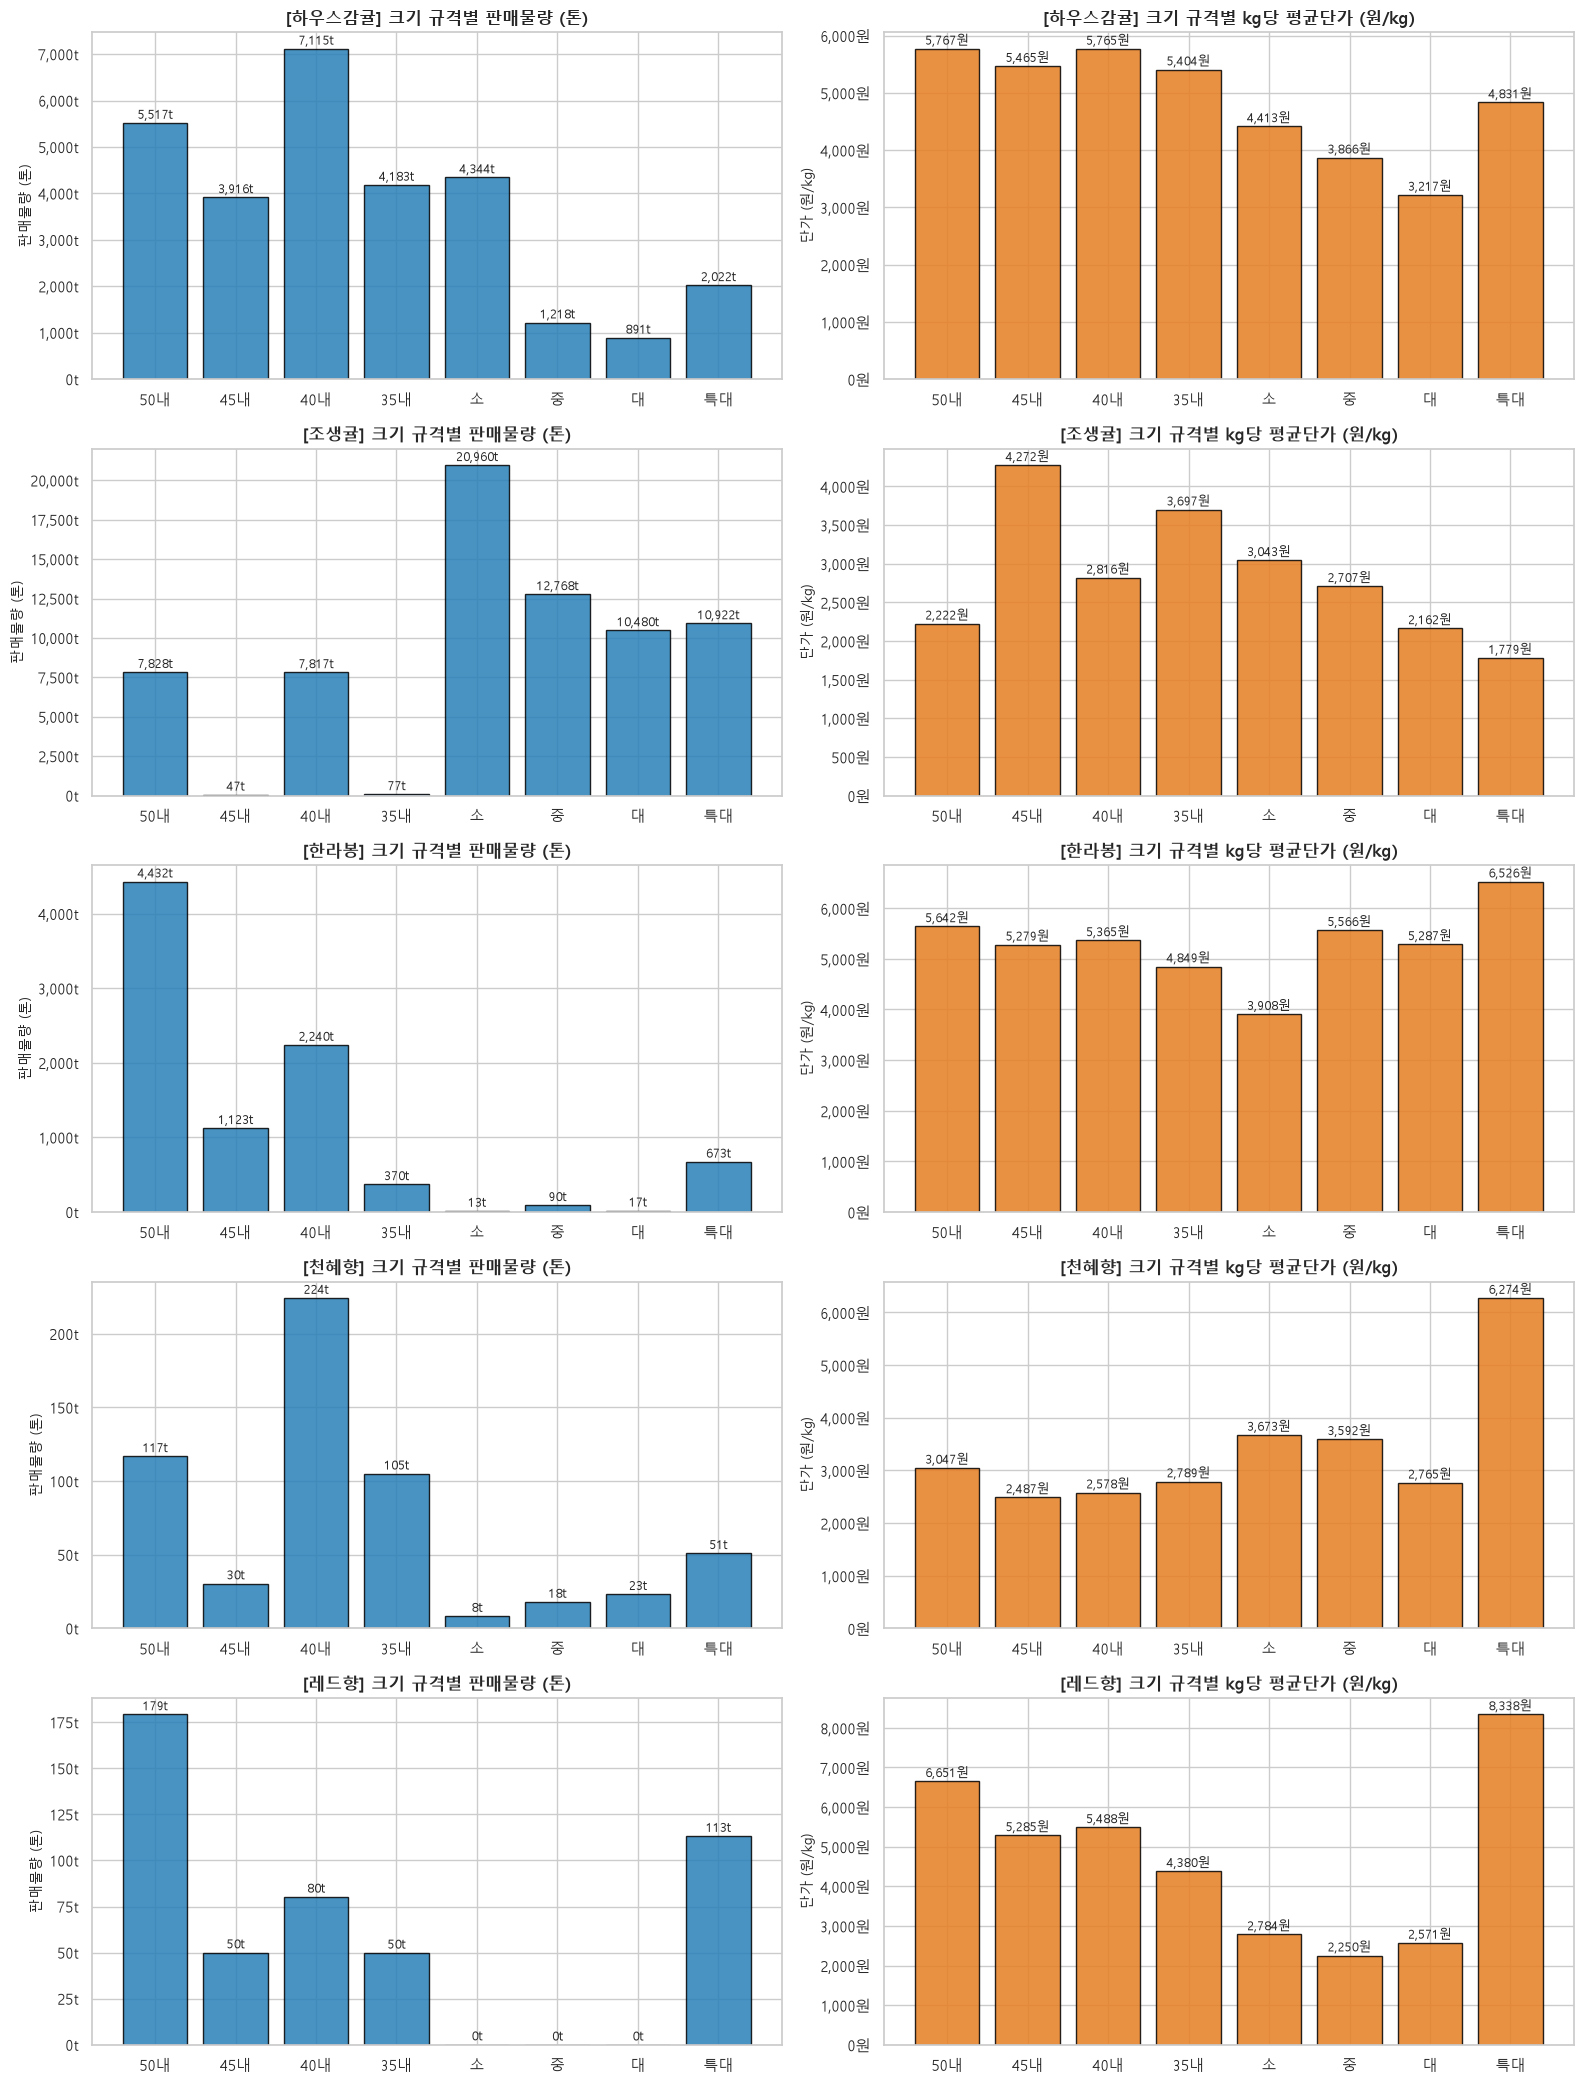

In [18]:
# 8-3) 【품종별 크기 분류 시각화】 주요 5대 품종별 크기 규격(지정 순서) 판매물량 및 판매단가 패널 차트
fig, axes = plt.subplots(len(target_varieties), 2, figsize=(16, 4.2 * len(target_varieties)))

for idx, var in enumerate(target_varieties):
    sub_data = variety_size_summary_df[variety_size_summary_df['품종'] == var]
    
    ax_vol = axes[idx, 0]
    bars_v = ax_vol.bar(sub_data['size'], sub_data['총판매물량_톤'], color='#2980b9', edgecolor='black', alpha=0.85)
    ax_vol.set_title(f"[{var}] 크기 규격별 판매물량 (톤)", fontsize=12, fontweight='bold')
    ax_vol.set_ylabel("판매물량 (톤)", fontsize=10)
    ax_vol.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
    for b in bars_v:
        h = b.get_height()
        ax_vol.annotate(f"{h:,.0f}t", (b.get_x() + b.get_width() / 2, h), textcoords="offset points", xytext=(0, 3), ha='center', fontsize=9)
        
    ax_prc = axes[idx, 1]
    bars_p = ax_prc.bar(sub_data['size'], sub_data['kg당평균단가_원'], color='#e67e22', edgecolor='black', alpha=0.85)
    ax_prc.set_title(f"[{var}] 크기 규격별 kg당 평균단가 (원/kg)", fontsize=12, fontweight='bold')
    ax_prc.set_ylabel("단가 (원/kg)", fontsize=10)
    ax_prc.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
    for b in bars_p:
        h = b.get_height()
        ax_prc.annotate(f"{h:,.0f}원", (b.get_x() + b.get_width() / 2, h), textcoords="offset points", xytext=(0, 3), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

### 8-4) 【상자 크기별(3kg, 5kg, 10kg) × 과수 규격(50내/45내/40내/35내)】 품종별 평균가격 비교
> **분석 배경**: 상자의 포장 중량(3kg, 5kg, 10kg)에 따라 상자 내 과수(50내/45내/40내/35내)가 의미하는 **개별 과실 1개의 실제 중량과 크기**가 완전히 다릅니다.
> - **3kg 상자**: 35내(약 86g/개), 40내(약 75g/개), 45내(약 67g/개), 50내(약 60g/개) $
ightarrow$ 소과/소포장 중심 (주로 하우스감귤)
> - **5kg 상자**: 35내(약 143g/개), 40내(약 125g/개), 45내(약 111g/개), 50내(약 100g/개) $
ightarrow$ 중소과 중심 (조생귤, 하우스감귤)
> - **10kg 상자**: 35내(약 285g/개), 40내(약 250g/개), 45내(약 222g/개), 50내(약 200g/개) $
ightarrow$ 중대과/대과 중심 (천혜향, 레드향 등 만감류 대량 포장)
>
> 따라서 각 **품종별 × 상자크기별 × 과수규격별** kg당 평균단가(원/kg)와 상자당 평균가격(원/상자)을 비교 분석합니다.

In [19]:
# 8-4) 품종별 x 상자크기(3kg, 5kg, 10kg) x 과수규격(50내, 45내, 40내, 35내) 평균가격 집계
target_count_sizes = ['50내', '45내', '40내', '35내']
box_weights = [3.0, 5.0, 10.0]

sub_box = df[(df['size'].isin(target_count_sizes)) & (df['unit_weight'].isin(box_weights))].copy()
sub_box['box_weight'] = sub_box['unit_weight'].astype(int).astype(str) + 'kg'

major_citrus_vars = ['하우스감귤', '조생귤', '극조생감귤', '비가림감귤', '한라봉', '천혜향', '황금향', '레드향']
sub_box_major = sub_box[sub_box['variety'].isin(major_citrus_vars)].copy()

# 1) 품종 x 상자크기 x 과수규격 집계 테이블
box_size_agg = sub_box_major.groupby(['variety', 'box_weight', 'size']).agg(
    거래건수=('volume_kg', 'count'),
    총판매물량_톤=('volume_kg', lambda x: x.sum() / 1000.0),
    total_rev=('total_price', 'sum'),
    total_kg=('volume_kg', 'sum'),
    상자당평균가격=('box_price', 'mean')
).reset_index()

box_size_agg['kg당평균단가'] = (box_size_agg['total_rev'] / (box_size_agg['total_kg'] + 1e-8)).round(0)
box_size_agg['상자당평균가격'] = box_size_agg['상자당평균가격'].round(0)

# 2) 피벗 테이블: kg당 평균단가 (원/kg)
pivot_kg_price = box_size_agg.pivot_table(
    index=['variety', 'box_weight'],
    columns='size',
    values='kg당평균단가'
)[target_count_sizes]

# 3) 피벗 테이블: 상자당 평균가격 (원/상자)
pivot_box_price = box_size_agg.pivot_table(
    index=['variety', 'box_weight'],
    columns='size',
    values='상자당평균가격'
)[target_count_sizes]

print("=== 【1】 품종별 x 상자크기별 x 과수규격별 kg당 평균단가 (원/kg) ===")
display(pivot_kg_price.rename_axis(index={'variety': '품종', 'box_weight': '상자크기'}))

print("\n=== 【2】 품종별 x 상자크기별 x 과수규격별 상자당 평균가격 (원/상자) ===")
display(pivot_box_price.rename_axis(index={'variety': '품종', 'box_weight': '상자크기'}))

=== 【1】 품종별 x 상자크기별 x 과수규격별 kg당 평균단가 (원/kg) ===


size           50내     45내     40내     35내
품종    상자크기                                
극조생감귤 10kg  1368.0     NaN  1643.0     NaN
      3kg   3558.0  3796.0  3912.0  3602.0
      5kg   1746.0  1371.0  2008.0  1111.0
레드향   10kg  5857.0  5105.0  4110.0  3150.0
      3kg   3667.0     NaN  5000.0  6585.0
      5kg   4744.0  4383.0  5214.0  5017.0
비가림감귤 10kg  1913.0     NaN  1399.0     NaN
      3kg   6531.0  4890.0  5769.0  5172.0
      5kg   3185.0  2790.0  3632.0  2877.0
조생귤   10kg  1194.0  3400.0  1501.0  3442.0
      3kg   4656.0  5297.0  4680.0  4006.0
      5kg   2259.0  2302.0  2858.0  2007.0
천혜향   10kg  3214.0  2584.0  2247.0  2477.0
      3kg   3970.0  2460.0  3023.0  2270.0
      5kg   1985.0  2328.0  2598.0  2804.0
하우스감귤 10kg  3117.0  1152.0  2178.0   925.0
      3kg   6292.0  6117.0  6186.0  6019.0
      5kg   4195.0  4094.0  3440.0  3018.0
한라봉   10kg  4934.0  4852.0  4755.0  4311.0
      3kg   6974.0  9775.0  1667.0  4517.0
      5kg   4536.0  3932.0  3794.0  4385.0
황금향   10kg  3670.0  3452.0  3037.0  3100.0
      3kg   5838.0  5478.0  5285.0  5162.0
      5kg   4254.0  4120.0  4649.0  3444.0


=== 【2】 품종별 x 상자크기별 x 과수규격별 상자당 평균가격 (원/상자) ===


size            50내      45내      40내      35내
품종    상자크기                                    
극조생감귤 10kg  12670.0      NaN  15352.0      NaN
      3kg   11225.0  11474.0  12704.0  11316.0
      5kg    8793.0   6917.0   9477.0   5847.0
레드향   10kg  48357.0  45680.0  38494.0  32616.0
      3kg   11000.0      NaN  15000.0  13000.0
      5kg   22761.0  19619.0  25134.0  24323.0
비가림감귤 10kg  14214.0      NaN  10417.0      NaN
      3kg   16112.0  14644.0  15737.0  14950.0
      5kg   15799.0  13619.0  18037.0  12250.0
조생귤   10kg  10890.0  34000.0  14186.0  34500.0
      3kg   13829.0  16164.0  15241.0  13415.0
      5kg   10990.0  14907.0  12453.0  12231.0
천혜향   10kg  27569.0  25398.0  21566.0  22705.0
      3kg   13684.0   6900.0   7258.0   6628.0
      5kg    9246.0  10656.0  12142.0  13544.0
하우스감귤 10kg  34790.0  14350.0  29324.0   8750.0
      3kg   18982.0  18941.0  19822.0  18878.0
      5kg   21382.0  21164.0  17907.0  15354.0
한라봉   10kg  47455.0  48079.0  46657.0  42345.0
      3kg   21344.0  26000.0   5000.0  14250.0
      5kg   19058.0  18074.0  18826.0  20799.0
황금향   10kg  41121.0  37012.0  33500.0  29000.0
      3kg   15558.0  14247.0  15127.0  14893.0
      5kg   19637.0  16832.0  21884.0  15401.0

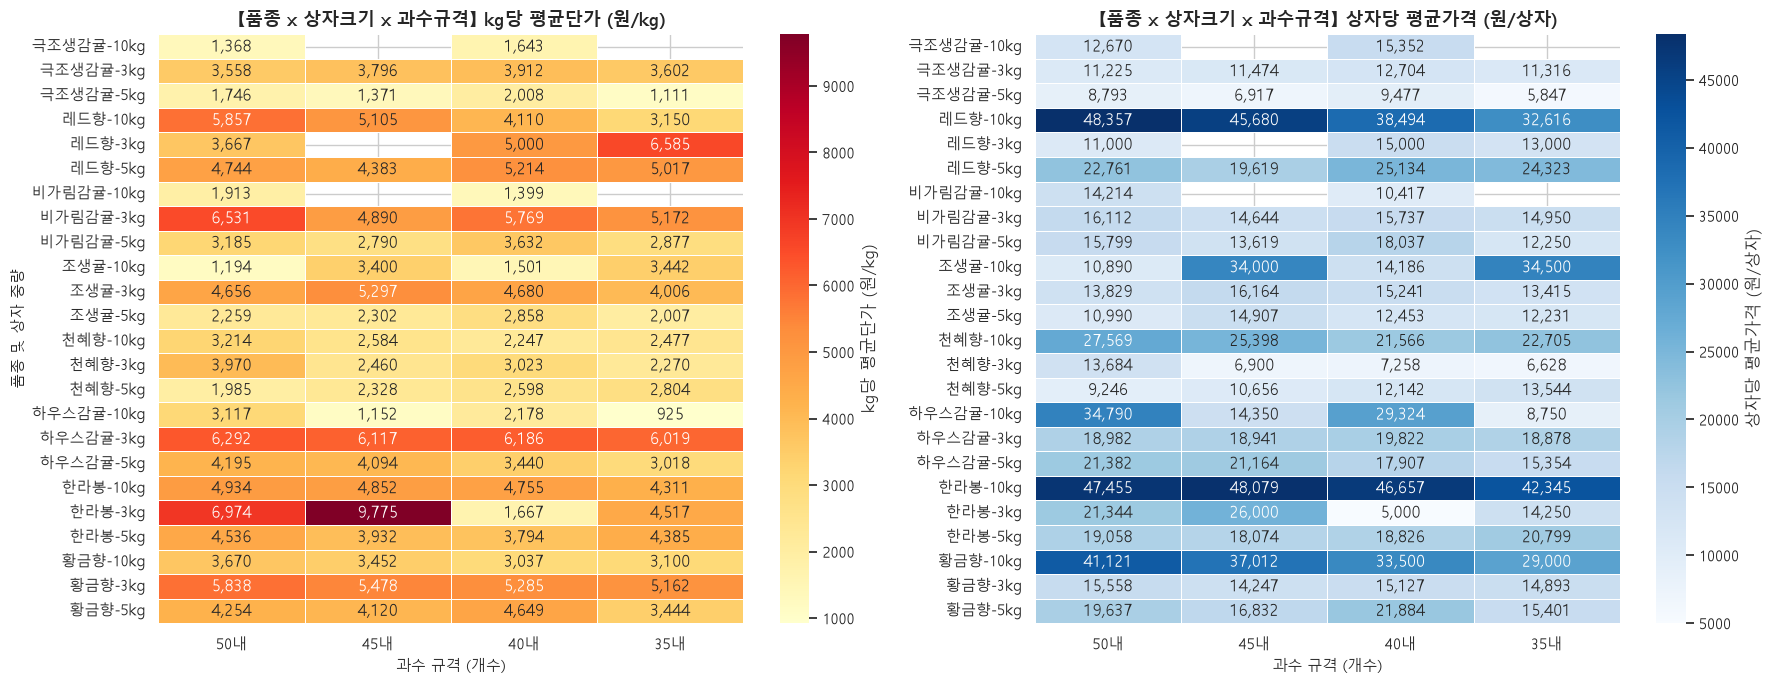

In [20]:
# 8-5) 상자크기별 과수규격 단가 비교 시각화 (히트맵 & 품종별 단가 비교)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# 히트맵: kg당 평균단가
sns.heatmap(pivot_kg_price, annot=True, fmt=',.0f', cmap='YlOrRd', ax=ax1, cbar_kws={'label': 'kg당 평균단가 (원/kg)'}, linewidths=0.5)
ax1.set_title("【품종 x 상자크기 x 과수규격】 kg당 평균단가 (원/kg)", fontsize=13, fontweight='bold')
ax1.set_xlabel("과수 규격 (개수)", fontsize=11)
ax1.set_ylabel("품종 및 상자 중량", fontsize=11)

# 히트맵: 상자당 평균가격
sns.heatmap(pivot_box_price, annot=True, fmt=',.0f', cmap='Blues', ax=ax2, cbar_kws={'label': '상자당 평균가격 (원/상자)'}, linewidths=0.5)
ax2.set_title("【품종 x 상자크기 x 과수규격】 상자당 평균가격 (원/상자)", fontsize=13, fontweight='bold')
ax2.set_xlabel("과수 규격 (개수)", fontsize=11)
ax2.set_ylabel("", fontsize=11)

plt.tight_layout()
plt.show()

## 9. [크기별 × 품종별] 항목별 날짜에 따른 거래량 및 가격 시계열 추이 분석
- **분석 개요**: 8번에서 지정 순서(`50내 -> 45내 -> 40내 -> 35내 -> 소 -> 중 -> 대 -> 특대`)로 분류된 주요 크기 항목들에 대해, **날짜별(월별 시계열) 거래물량과 가격의 변화 추이를 시각화**합니다.
- **분석 항목**:
  1. **[월별 거래물량 추이]**: 품종별(하우스감귤, 조생귤, 한라봉 등) 지정 크기 항목의 월별 거래물량(톤) 시계열 변화
  2. **[월별 판매가격 추이]**: 품종별 지정 크기 항목의 월별 kg당 평균단가(원/kg) 시계열 변화 (크기별 프리미엄 및 계절 가격 변동)
  3. **[핵심 품종별 거래물량 & 가격 2축(Dual-Axis) 시계열]**: 대표 품종(하우스감귤, 조생귤) 내 핵심 크기 항목의 날짜별 수급-가격 상관 추이
  4. **[복합 교차 히트맵]**: 품종 × 등급, 품종 × 크기별(지정 순서 적용) 평균단가 히트맵

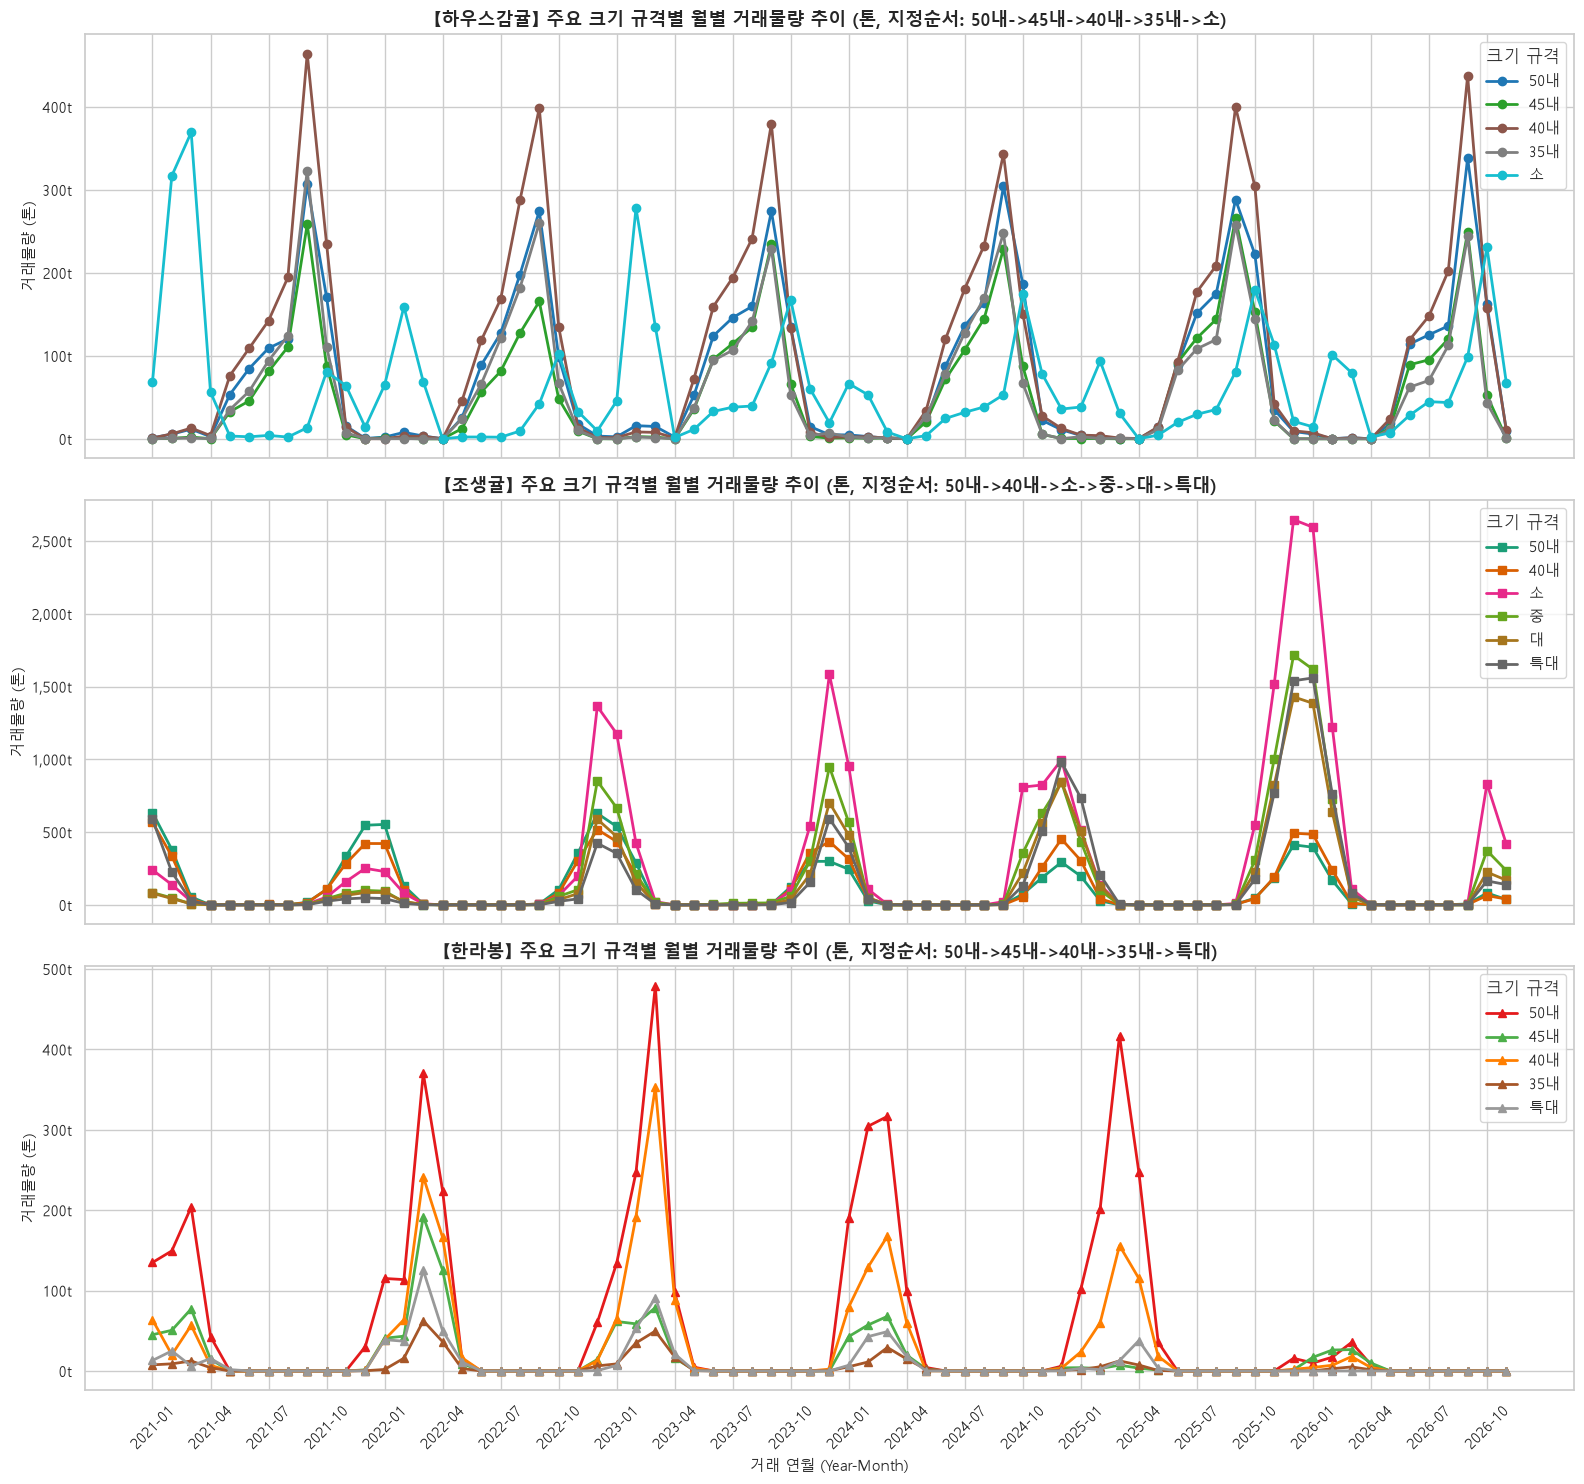

In [21]:
# 9-1) 【품종별 크기 항목】 월별 거래물량(톤) 시계열 추이 그래프 (전체 기간 71개월 시계열 동기화)
fig, axes = plt.subplots(3, 1, figsize=(16, 15), sharex=True)

all_months = sorted(df['year_month'].unique())
size_order = ['50내', '45내', '40내', '35내', '소', '중', '대', '특대']

# 1) 하우스감귤: 지정 순서 중 상위 규격 (전체 71개월 reindex)
house_sizes = [s for s in size_order if s in ['50내', '45내', '40내', '35내', '소']]
house_ts = df[(df['variety'] == '하우스감귤') & (df['size'].isin(house_sizes))].groupby(['year_month', 'size'])['volume_kg'].sum().unstack(fill_value=0) / 1000.0
house_ts = house_ts.reindex(index=all_months, fill_value=0.0).reindex(columns=house_sizes)

house_ts.plot(ax=axes[0], marker='o', linewidth=2, colormap='tab10')
axes[0].set_title("【하우스감귤】 주요 크기 규격별 월별 거래물량 추이 (톤, 지정순서: 50내->45내->40내->35내->소)", fontsize=13, fontweight='bold')
axes[0].set_ylabel("거래물량 (톤)", fontsize=11)
axes[0].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
axes[0].legend(title='크기 규격', loc='upper right')

# 2) 조생귤: 지정 순서 중 상위 규격 (전체 71개월 reindex)
joseng_sizes = [s for s in size_order if s in ['50내', '40내', '소', '중', '대', '특대']]
joseng_ts = df[(df['variety'] == '조생귤') & (df['size'].isin(joseng_sizes))].groupby(['year_month', 'size'])['volume_kg'].sum().unstack(fill_value=0) / 1000.0
joseng_ts = joseng_ts.reindex(index=all_months, fill_value=0.0).reindex(columns=joseng_sizes)

joseng_ts.plot(ax=axes[1], marker='s', linewidth=2, colormap='Dark2')
axes[1].set_title("【조생귤】 주요 크기 규격별 월별 거래물량 추이 (톤, 지정순서: 50내->40내->소->중->대->특대)", fontsize=13, fontweight='bold')
axes[1].set_ylabel("거래물량 (톤)", fontsize=11)
axes[1].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
axes[1].legend(title='크기 규격', loc='upper right')

# 3) 한라봉(코드 07): 지정 순서 중 상위 규격 (전체 71개월 reindex)
halla_sizes = [s for s in size_order if s in ['50내', '45내', '40내', '35내', '특대']]
halla_ts = df[(df['variety'] == '한라봉') & (df['size'].isin(halla_sizes))].groupby(['year_month', 'size'])['volume_kg'].sum().unstack(fill_value=0) / 1000.0
halla_ts = halla_ts.reindex(index=all_months, fill_value=0.0).reindex(columns=halla_sizes)

halla_ts.plot(ax=axes[2], marker='^', linewidth=2, colormap='Set1')
axes[2].set_title("【한라봉】 주요 크기 규격별 월별 거래물량 추이 (톤, 지정순서: 50내->45내->40내->35내->특대)", fontsize=13, fontweight='bold')
axes[2].set_ylabel("거래물량 (톤)", fontsize=11)
axes[2].set_xlabel("거래 연월 (Year-Month)", fontsize=11)
axes[2].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
axes[2].legend(title='크기 규격', loc='upper right')

tick_idx = list(range(0, len(all_months), 3))
axes[2].set_xticks(tick_idx)
axes[2].set_xticklabels([all_months[i] for i in tick_idx], rotation=45)

plt.tight_layout()
plt.show()

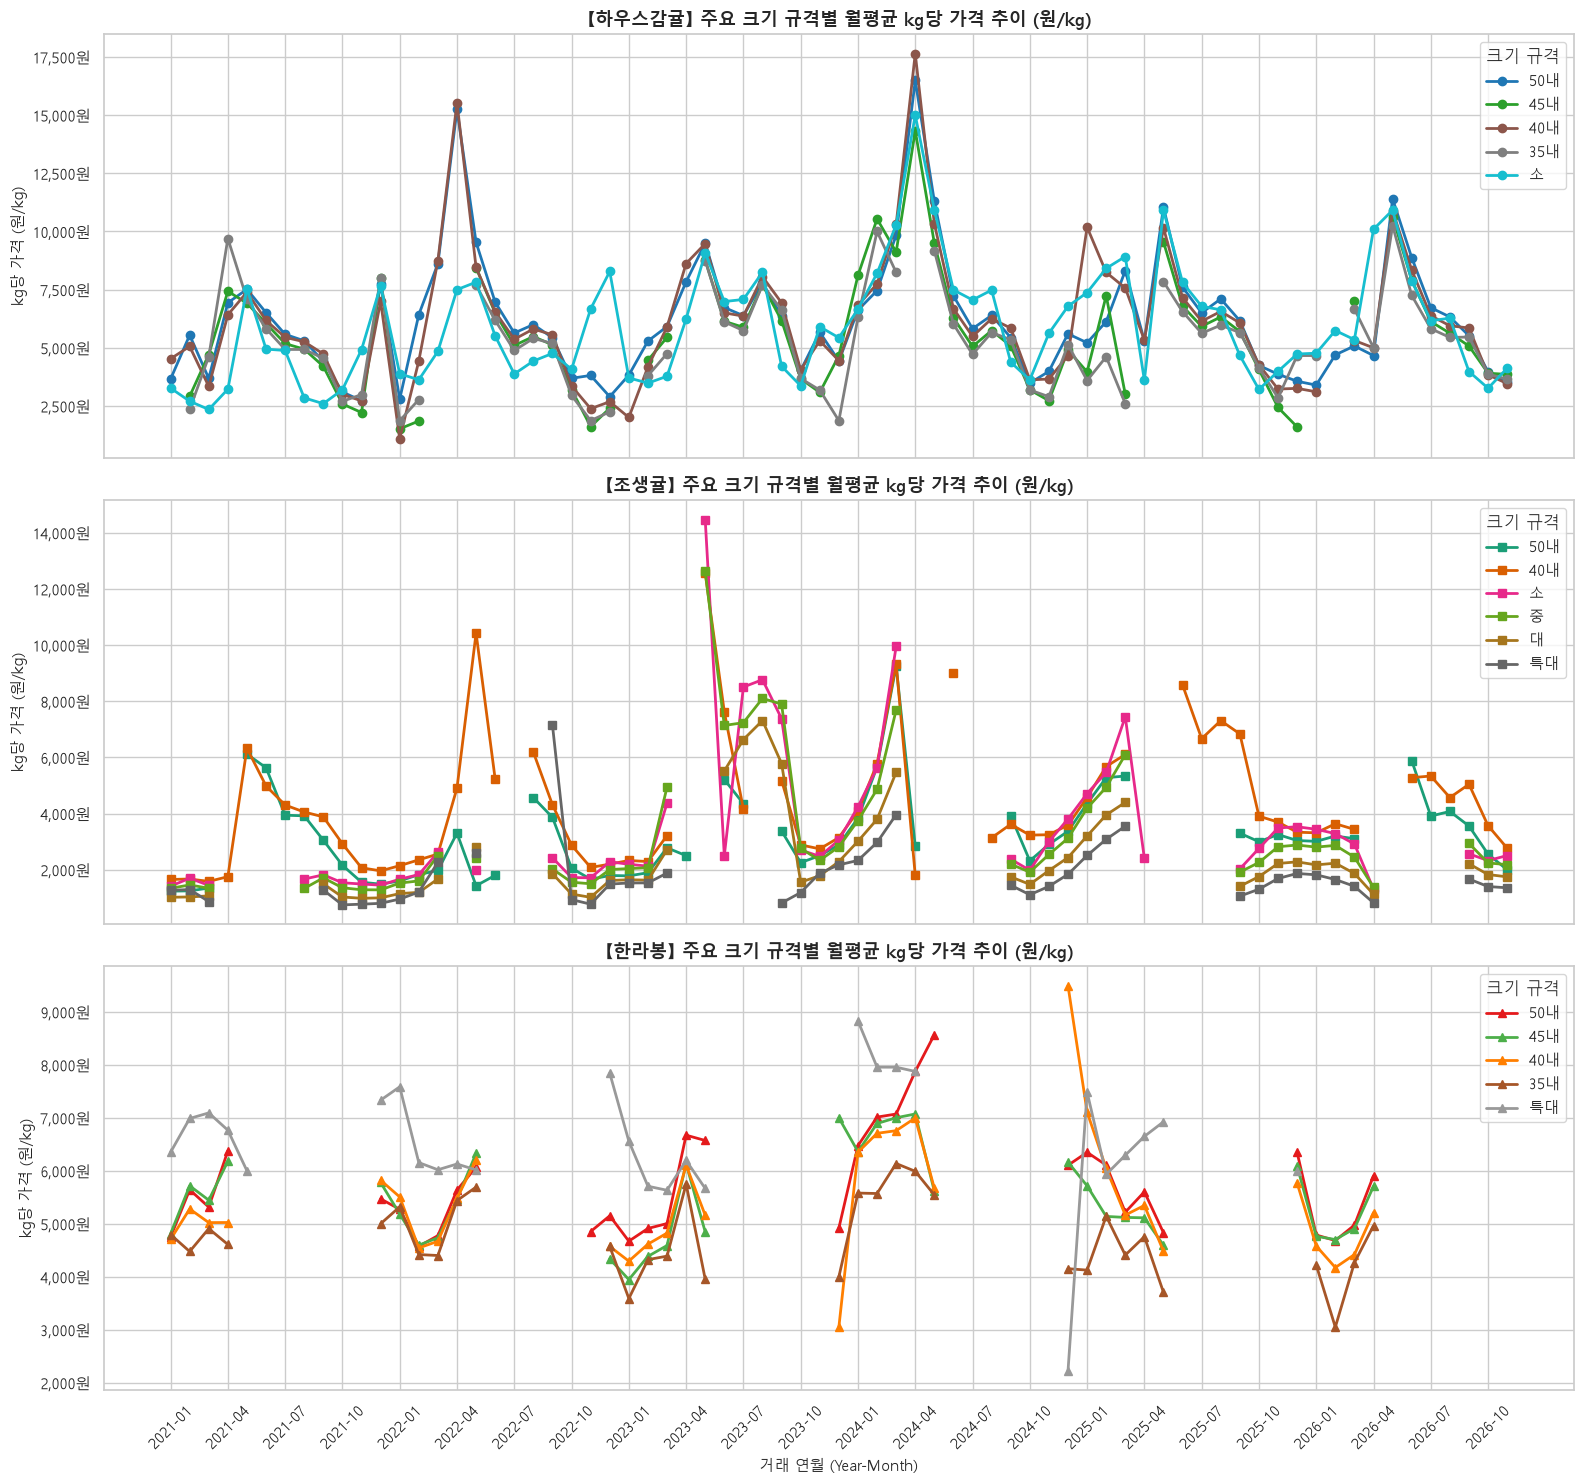

In [22]:
# 9-2) 【품종별 크기 항목】 월별 kg당 평균 판매가격(원/kg) 시계열 추이 그래프 (전체 기간 71개월 시계열 동기화)
fig, axes = plt.subplots(3, 1, figsize=(16, 15), sharex=True)

def calc_unit_price_ts(variety_name, sizes):
    sub = df[(df['variety'] == variety_name) & (df['size'].isin(sizes))]
    grouped = sub.groupby(['year_month', 'size']).agg(vol=('volume_kg', 'sum'), price=('total_price', 'sum')).reset_index()
    grouped['unit_price'] = grouped['price'] / (grouped['vol'] + 1e-8)
    p = grouped.pivot(index='year_month', columns='size', values='unit_price')
    p = p.reindex(index=all_months)  # 71개월 전체 시계열 축 동기화
    return p.reindex(columns=[s for s in sizes if s in p.columns])

house_prc_ts = calc_unit_price_ts('하우스감귤', house_sizes)
house_prc_ts.plot(ax=axes[0], marker='o', linewidth=2, colormap='tab10')
axes[0].set_title("【하우스감귤】 주요 크기 규격별 월평균 kg당 가격 추이 (원/kg)", fontsize=13, fontweight='bold')
axes[0].set_ylabel("kg당 가격 (원/kg)", fontsize=11)
axes[0].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
axes[0].legend(title='크기 규격', loc='upper right')

joseng_prc_ts = calc_unit_price_ts('조생귤', joseng_sizes)
joseng_prc_ts.plot(ax=axes[1], marker='s', linewidth=2, colormap='Dark2')
axes[1].set_title("【조생귤】 주요 크기 규격별 월평균 kg당 가격 추이 (원/kg)", fontsize=13, fontweight='bold')
axes[1].set_ylabel("kg당 가격 (원/kg)", fontsize=11)
axes[1].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
axes[1].legend(title='크기 규격', loc='upper right')

halla_prc_ts = calc_unit_price_ts('한라봉', halla_sizes)
halla_prc_ts.plot(ax=axes[2], marker='^', linewidth=2, colormap='Set1')
axes[2].set_title("【한라봉】 주요 크기 규격별 월평균 kg당 가격 추이 (원/kg)", fontsize=13, fontweight='bold')
axes[2].set_ylabel("kg당 가격 (원/kg)", fontsize=11)
axes[2].set_xlabel("거래 연월 (Year-Month)", fontsize=11)
axes[2].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
axes[2].legend(title='크기 규격', loc='upper right')

tick_idx = list(range(0, len(all_months), 3))
axes[2].set_xticks(tick_idx)
axes[2].set_xticklabels([all_months[i] for i in tick_idx], rotation=45)

plt.tight_layout()
plt.show()

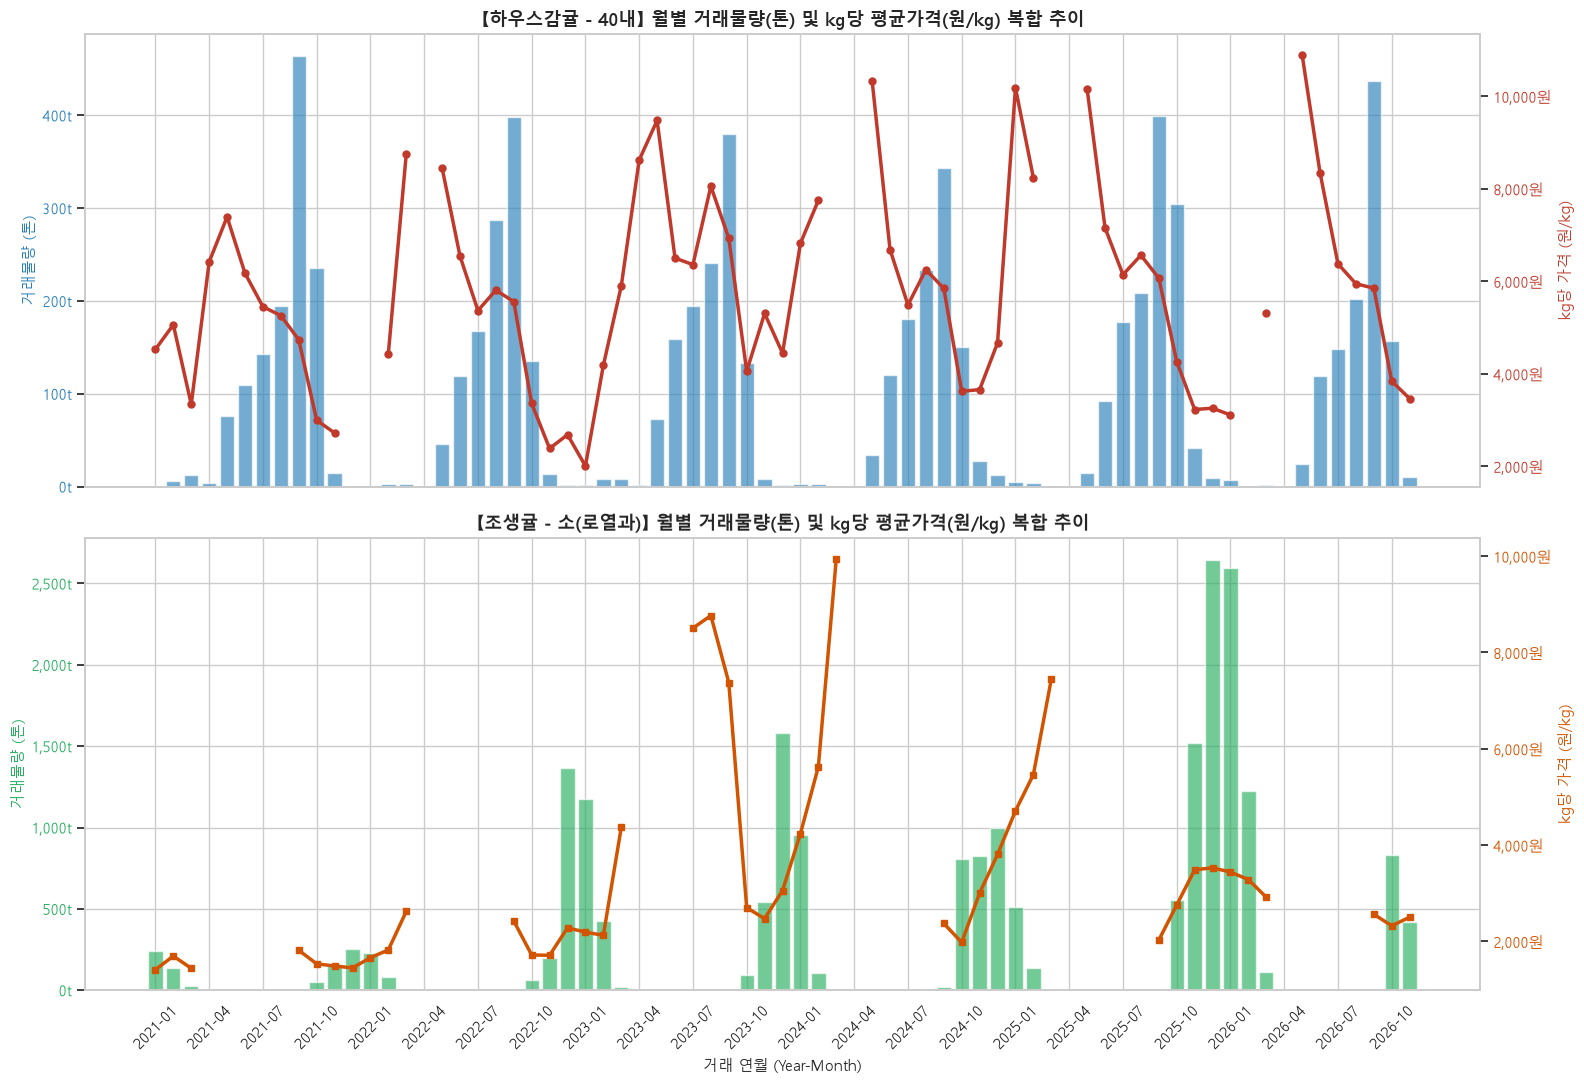

In [23]:
# 9-3) 【대표 품종 x 크기 규격】 날짜별 거래물량 & 판매가격 복합(Dual-Axis) 시계열 추이 (71개월 시계열 동기화 & 비출하기 노이즈 정제)
fig, (ax1, ax3) = plt.subplots(2, 1, figsize=(16, 11), sharex=True)

all_months = sorted(df['year_month'].unique())
x_indices = np.arange(len(all_months))

# (1) [하우스감귤 - 40내 규격] 월별 거래물량 및 가격 추이 (전체 71개월 reindex)
sub_h40 = df[(df['variety'] == '하우스감귤') & (df['size'] == '40내')].groupby('year_month').agg(
    vol_ton=('volume_kg', lambda x: x.sum() / 1000.0),
    total_rev=('total_price', 'sum'),
    total_kg=('volume_kg', 'sum')
).reindex(all_months).fillna({'vol_ton': 0.0, 'total_rev': 0.0, 'total_kg': 0.0})
sub_h40['unit_price'] = np.where(sub_h40['vol_ton'] >= 1.0, sub_h40['total_rev'] / (sub_h40['total_kg'] + 1e-8), np.nan)

color_vol1 = '#2980b9'
color_prc1 = '#c0392b'

ax1.bar(x_indices, sub_h40['vol_ton'], color=color_vol1, alpha=0.65, label='거래물량 (톤)')
ax1.set_ylabel('거래물량 (톤)', color=color_vol1, fontsize=11)
ax1.tick_params(axis='y', labelcolor=color_vol1)
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
ax1.set_title("【하우스감귤 - 40내】 월별 거래물량(톤) 및 kg당 평균가격(원/kg) 복합 추이", fontsize=13, fontweight='bold')

ax2 = ax1.twinx()
ax2.plot(x_indices, sub_h40['unit_price'], color=color_prc1, marker='o', linewidth=2.5, markersize=5, label='kg당 가격 (원/kg)')
ax2.set_ylabel('kg당 가격 (원/kg)', color=color_prc1, fontsize=11)
ax2.tick_params(axis='y', labelcolor=color_prc1)
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
ax2.grid(False)

# (2) [조생귤 - 소 규격] 월별 거래물량 및 가격 추이 (전체 71개월 reindex & 비출하기 극소수 이상치 정제)
sub_j_so = df[(df['variety'] == '조생귤') & (df['size'] == '소')].groupby('year_month').agg(
    vol_ton=('volume_kg', lambda x: x.sum() / 1000.0),
    total_rev=('total_price', 'sum'),
    total_kg=('volume_kg', 'sum')
).reindex(all_months).fillna({'vol_ton': 0.0, 'total_rev': 0.0, 'total_kg': 0.0})
sub_j_so['unit_price'] = np.where(sub_j_so['vol_ton'] >= 1.0, sub_j_so['total_rev'] / (sub_j_so['total_kg'] + 1e-8), np.nan)

color_vol2 = '#27ae60'
color_prc2 = '#d35400'

ax3.bar(x_indices, sub_j_so['vol_ton'], color=color_vol2, alpha=0.65, label='거래물량 (톤)')
ax3.set_ylabel('거래물량 (톤)', color=color_vol2, fontsize=11)
ax3.tick_params(axis='y', labelcolor=color_vol2)
ax3.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}t"))
ax3.set_title("【조생귤 - 소(로열과)】 월별 거래물량(톤) 및 kg당 평균가격(원/kg) 복합 추이", fontsize=13, fontweight='bold')
ax3.set_xlabel("거래 연월 (Year-Month)", fontsize=11)

ax4 = ax3.twinx()
ax4.plot(x_indices, sub_j_so['unit_price'], color=color_prc2, marker='s', linewidth=2.5, markersize=5, label='kg당 가격 (원/kg)')
ax4.set_ylabel('kg당 가격 (원/kg)', color=color_prc2, fontsize=11)
ax4.tick_params(axis='y', labelcolor=color_prc2)
ax4.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"{int(x):,}원"))
ax4.grid(False)

tick_idx = list(range(0, len(all_months), 3))
ax3.set_xticks(tick_idx)
ax3.set_xticklabels([all_months[i] for i in tick_idx], rotation=45)

plt.tight_layout()
plt.show()

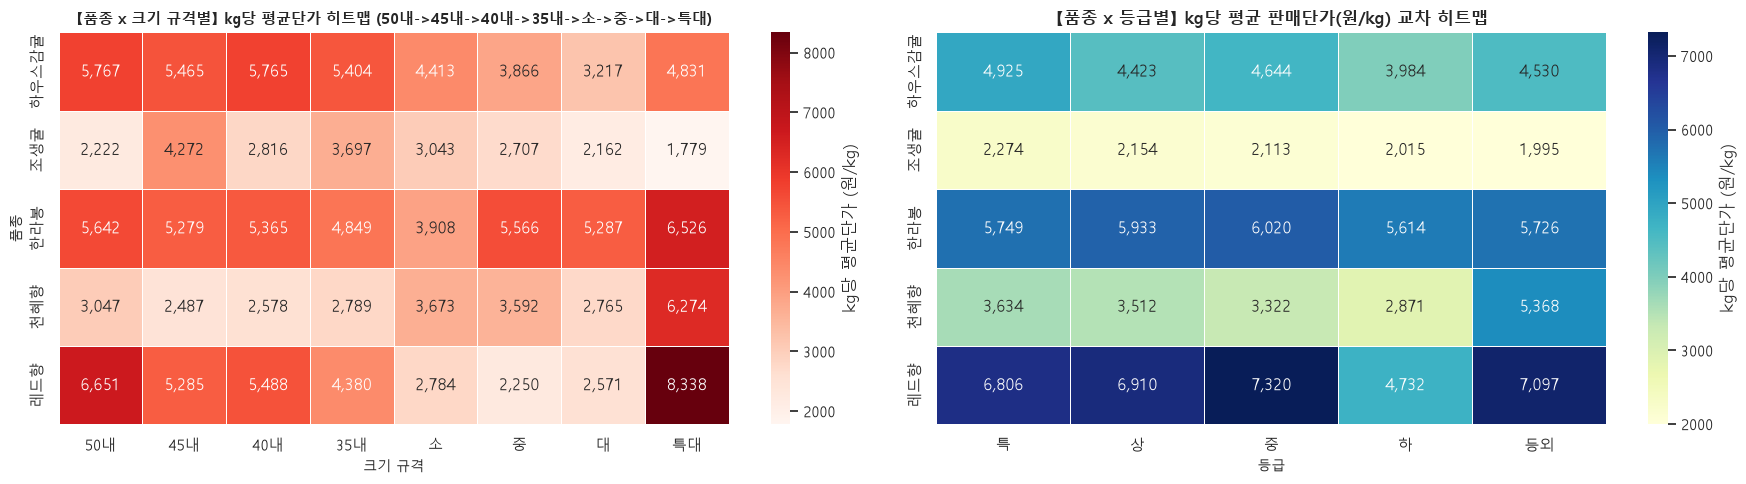

In [24]:
# 9-4) [품종 x 크기], [품종 x 등급] 교차 평균단가 히트맵 (크기 지정 순서 적용)
top_5_vars = ['하우스감귤', '조생귤', '한라봉', '천혜향', '레드향']
main_sizes_for_cross = ['50내', '45내', '40내', '35내', '소', '중', '대', '특대']

fig, (ax_h1, ax_h2) = plt.subplots(1, 2, figsize=(18, 5))

cross_sz_df = df[df['variety'].isin(top_5_vars) & df['size'].isin(main_sizes_for_cross)].copy()
pivot_sz = cross_sz_df.pivot_table(index='variety', columns='size', values=['total_price', 'volume_kg'], aggfunc='sum')
pivot_sz_unit = (pivot_sz['total_price'] / (pivot_sz['volume_kg'] + 1e-8)).reindex(index=top_5_vars, columns=main_sizes_for_cross)

sns.heatmap(pivot_sz_unit, annot=True, fmt=',.0f', cmap='Reds', ax=ax_h1, cbar_kws={'label': 'kg당 평균단가 (원/kg)'}, linewidths=0.5)
ax_h1.set_title("【품종 x 크기 규격별】 kg당 평균단가 히트맵 (50내->45내->40내->35내->소->중->대->특대)", fontsize=11, fontweight='bold')
ax_h1.set_xlabel("크기 규격", fontsize=10)
ax_h1.set_ylabel("품종", fontsize=10)

main_5_grades = ['특', '상', '중', '하', '등외']
cross_gr_df = df[df['variety'].isin(top_5_vars) & df['grade'].isin(main_5_grades)].copy()
pivot_gr = cross_gr_df.pivot_table(index='variety', columns='grade', values=['total_price', 'volume_kg'], aggfunc='sum')
pivot_gr_unit = (pivot_gr['total_price'] / (pivot_gr['volume_kg'] + 1e-8)).reindex(index=top_5_vars, columns=main_5_grades)

sns.heatmap(pivot_gr_unit, annot=True, fmt=',.0f', cmap='YlGnBu', ax=ax_h2, cbar_kws={'label': 'kg당 평균단가 (원/kg)'}, linewidths=0.5)
ax_h2.set_title("【품종 x 등급별】 kg당 평균 판매단가(원/kg) 교차 히트맵", fontsize=12, fontweight='bold')
ax_h2.set_xlabel("등급", fontsize=10)
ax_h2.set_ylabel("", fontsize=10)

plt.tight_layout()
plt.show()

## 10. 전처리 완료 데이터 내보내기 (Export)
- 정제 및 파생변수(`trd_type`, `is_auction` 등) 생성이 완료된 데이터프레임을 저장합니다.
  1. `data/preprocessed_citrus_data.csv`: 전체 정제 거래 데이터
  2. `data/preprocessed_citrus_data_auction_only.csv`: **수의계약이 제외된 순수 경매 전용 데이터**
- 다음 단계인 머신러닝/딥러닝 모델링(예: TFT, 시계열 예측)에 바로 활용할 수 있습니다.

In [25]:
# 전처리 완료 데이터 저장
output_clean_path = data_dir / "preprocessed_citrus_data.csv"
output_auction_path = data_dir / "preprocessed_citrus_data_auction_only.csv"

export_cols = [
    'date', 'year', 'month', 'year_month', 'weekday',
    'whsl_mrkt_cd', 'whsl_mrkt_nm',
    'trd_se', 'trd_type', 'is_auction', 'is_negotiated',
    'gds_sclsf_cd', 'variety',
    'grd_cd', 'grade',
    'sz_cd', 'size',
    'pkg_nm', 'unit_weight',
    'volume_kg', 'box_qty',
    'box_price', 'total_price', 'unit_price_kg'
]

export_cols = [c for c in export_cols if c in df.columns]

print(f"1) 전체 전처리 데이터 저장 시작: {output_clean_path.resolve()}")
t0 = time.time()
df[export_cols].to_csv(output_clean_path, index=False, encoding='utf-8-sig')
print(f"전체 CSV 저장 완료! 소요시간: {time.time() - t0:.2f}초 ({len(df):,}건, {output_clean_path.stat().st_size / (1024*1024):.2f} MB)")

# 2) 수의계약 제외(경매 전용) 데이터 저장
print(f"\n2) 수의계약 제외(경매 전용) 데이터 저장 시작: {output_auction_path.resolve()}")
t0 = time.time()
df_auction_export = df[df['trd_type'] != '수의계약'][export_cols]
df_auction_export.to_csv(output_auction_path, index=False, encoding='utf-8-sig')
print(f"경매 전용 CSV 저장 완료! 소요시간: {time.time() - t0:.2f}초 ({len(df_auction_export):,}건, {output_auction_path.stat().st_size / (1024*1024):.2f} MB)")

1) 전체 전처리 데이터 저장 시작: D:\aiproject\ugasungsi\data\preprocessed_citrus_data.csv
전체 CSV 저장 완료! 소요시간: 5.55초 (1,243,424건, 199.44 MB)

2) 수의계약 제외(경매 전용) 데이터 저장 시작: D:\aiproject\ugasungsi\data\preprocessed_citrus_data_auction_only.csv
경매 전용 CSV 저장 완료! 소요시간: 4.80초 (1,057,583건, 167.47 MB)
